# Ablation Study — Descriptive Analysis

This notebook performs descriptive analysis and visualization of the ablation scenarios: **Baseline, SMOTE, GA, and SMOTE+GA**.

The notebook:
- Standardizes fold-level results from the source CSV files.
- Displays a **separate performance table for each metric**, including the mean, standard deviation (SD), and 95% confidence interval (CI).
- Saves **one CSV file per metric**, including a `Mean ± SD [95% CI]` column for convenient use in the paper.
- Generates **a separate plot for each metric**, with one panel per model and individual fold observations.
- Summarizes confusion-matrix counts (TN, FP, FN, TP) and runtime when available.
- Displays result tables directly in the notebook as well as saving the output files.

**Interpretation note:** The 95% CI is a descriptive t-based interval calculated from fold scores. Cross-validation folds may be dependent, so this interval describes variation in fold scores and should not be interpreted as fully independent statistical inference. This notebook does not perform hypothesis testing.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

DATA_DIR = Path.cwd()
OUTPUT_DIR = DATA_DIR / "ablation_descriptive_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Models retained in the main analysis.
MODELS = ["Logistic Regression", "SVM", "Random Forest", "XGBoost"]
SCENARIOS = ["Baseline", "SMOTE", "GA", "SMOTE+GA"]

# Performance metrics; confusion-matrix counts and runtime are summarized separately.
METRICS = [
    "Accuracy", 
    "Precision", 
    "Recall", 
    "Specificity", 
    "F1",
    "ROC_AUC", 
    "Average_Precision", 
    "PR_AUC",
    "Balanced_Accuracy", 
    "MCC"
]

# Source CSV filenames expected in the notebook working directory.
FILES = {
    "Baseline": "baseline_repeated_fold_results.csv",
    "SMOTE": "smote_fold_results.csv",
    "GA": "ga_fold_results.csv",
    
}

# SMOTE+GA results are loaded only from this source file.
SMOTE_GA_FILE = "smote_ga_fold_results.csv"

print("Folder input :", DATA_DIR)
print("Folder output:", OUTPUT_DIR)
print("Ensure the required source CSV files are present in the input folder.")

Folder input : D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9
Folder output: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs
Pastikan semua CSV yang diperlukan ada di folder input.


## 1. Functions for standardizing source files

The loaders convert wide-format results (metric columns grouped by model) into long format. Fold-level rows are retained; folds are not matched across scenarios because this notebook performs descriptive analysis.

In [2]:
def require_file(filename):
    path = DATA_DIR / filename
    if not path.exists():
        raise FileNotFoundError(
            f"File '{filename}' tidak ditemukan di {DATA_DIR}. "
            "Periksa nama file atau ubah konfigurasi FILES/SMOTE_GA_FILES."
        )
    return path


def add_sample_order(df):
    df = df.copy()
    sort_cols = [c for c in ["Repeat", "Fold", "Outer_Fold"] if c in df.columns]
    if sort_cols:
        df = df.sort_values(sort_cols, kind="stable").reset_index(drop=True)
    df["Fold_Index"] = np.arange(1, len(df) + 1)
    return df


def normalize_metric_name(name):
    mapping = {
        "accuracy": "Accuracy",
        "precision": "Precision",
        "recall": "Recall",
        "specificity": "Specificity",
        "f1": "F1",
        "roc_auc": "ROC_AUC",
        "average_precision": "Average_Precision",
        "pr_auc": "PR_AUC",
        "balanced_accuracy": "Balanced_Accuracy",
        "mcc": "MCC",
    }
    return mapping.get(str(name).lower(), name)


import numpy as np
import pandas as pd
from scipy.stats import t

def summarize_values(values):
    x = pd.to_numeric(
        pd.Series(values), errors="coerce"
    ).dropna().to_numpy(dtype=float)

    n = len(x)

    if n == 0:
        return {
            "N": 0,
            "Mean": np.nan,
            "SD": np.nan,
            "CI95_Lower": np.nan,
            "CI95_Upper": np.nan,
            "Median": np.nan,
            "Min": np.nan,
            "Max": np.nan,
        }

    mean = float(np.mean(x))
    sd = float(np.std(x, ddof=1)) if n > 1 else np.nan

    if n > 1 and np.isfinite(sd):
        margin = t.ppf(0.975, df=n - 1) * sd / np.sqrt(n)
        lower = mean - margin
        upper = mean + margin
    else:
        lower, upper = np.nan, np.nan

    return {
        "N": n,
        "Mean": mean,
        "SD": sd,
        "CI95_Lower": lower,
        "CI95_Upper": upper,
        "Median": float(np.median(x)),
        "Min": float(np.min(x)),
        "Max": float(np.max(x)),
    }


def load_baseline(path):
    df = add_sample_order(pd.read_csv(path))
    rows = []
    for _, r in df.iterrows():
        row = {"Scenario": "Baseline", "Model": r["Model"], "Fold_Index": r["Fold_Index"]}
        for metric in METRICS:
            if metric in df.columns:
                row[metric] = r[metric]
        for col in ["Runtime_Seconds", "TN", "FP", "FN", "TP"]:
            if col in df.columns:
                row[col] = r[col]
        rows.append(row)
    return pd.DataFrame(rows)


def load_smote(path):
    df = add_sample_order(pd.read_csv(path))
    prefixes = {
        "LR": "Logistic Regression",
        "SVM": "SVM",
        "RF": "Random Forest",
        "XGB": "XGBoost",
    }
    rows = []
    for prefix, model in prefixes.items():
        metric_cols = {
            metric: f"{prefix}_{metric.lower()}"
            for metric in METRICS
            if f"{prefix}_{metric.lower()}" in df.columns
        }
        if not metric_cols:
            continue
        for _, r in df.iterrows():
            row = {"Scenario": "SMOTE", "Model": model, "Fold_Index": r["Fold_Index"]}
            for metric, col in metric_cols.items():
                row[metric] = r[col]
            runtime_cols = [
                f"{prefix}_Training_Runtime_Seconds",
                f"{prefix}_SMOTE_Runtime_Seconds",
            ]
            present = [c for c in runtime_cols if c in df.columns]
            if present:
                row["Runtime_Seconds"] = sum(
                    float(r[c]) for c in present if pd.notna(r[c])
                )
            for col in ["TN", "FP", "FN", "TP"]:
                source = f"{prefix}_{col}"
                if source in df.columns:
                    row[col] = r[source]
            rows.append(row)
    return pd.DataFrame(rows)


def load_ga(path):
    df = add_sample_order(pd.read_csv(path))
    model_names = ["Random Forest", "XGBoost", "Logistic Regression", "SVM"]
    rows = []
    for model in model_names:
        prefix = model
        metric_map = {
            "Accuracy": "accuracy", "Precision": "precision", "Recall": "recall",
            "Specificity": "specificity", "F1": "f1", "ROC_AUC": "roc_auc",
            "Average_Precision": "average_precision", "PR_AUC": "pr_auc",
            "Balanced_Accuracy": "balanced_accuracy", "MCC": "mcc",
        }
        available = {
            metric: f"{prefix}_{raw}"
            for metric, raw in metric_map.items()
            if f"{prefix}_{raw}" in df.columns
        }
        if not available:
            continue
        for _, r in df.iterrows():
            row = {"Scenario": "GA", "Model": model, "Fold_Index": r["Fold_Index"]}
            for metric, col in available.items():
                row[metric] = r[col]
            runtime_col = f"{prefix}_runtime_seconds"
            if runtime_col in df.columns:
                row["Runtime_Seconds"] = r[runtime_col]
            for col in ["TN", "FP", "FN", "TP"]:
                source = f"{prefix}_{col}"
                if source in df.columns:
                    row[col] = r[source]
            rows.append(row)
    return pd.DataFrame(rows)


def load_smote_ga(path):
    """Load SMOTE+GA results exclusively from smote_ga_fold_results.csv."""
    df = add_sample_order(pd.read_csv(path))
    metric_map = {
        "Accuracy": "accuracy", "Precision": "precision", "Recall": "recall",
        "Specificity": "specificity", "F1": "f1", "ROC_AUC": "roc_auc",
        "Average_Precision": "average_precision", "PR_AUC": "pr_auc",
        "Balanced_Accuracy": "balanced_accuracy", "MCC": "mcc",
    }
    model_prefixes = {
        "Logistic Regression": "Logistic Regression",
        "SVM": "SVM",
        "Random Forest": "Random Forest",
        "XGBoost": "XGBoost",
    }
    rows = []
    has_prefixed_metrics = any(
        f"{prefix}_{raw}" in df.columns
        for prefix in model_prefixes.values()
        for raw in metric_map.values()
    )

    if not has_prefixed_metrics:
        available = {
            metric: raw for metric, raw in metric_map.items()
            if raw in df.columns
        }
        if available:
            model = str(df["Model"].iloc[0]) if "Model" in df.columns and len(df) else "Unknown Model"
            model_prefixes = {model: ""}
        else:
            model_prefixes = {}

    for model, prefix in model_prefixes.items():
        available = {
            metric: f"{prefix}_{raw}" if prefix else raw
            for metric, raw in metric_map.items()
            if (f"{prefix}_{raw}" if prefix else raw) in df.columns
        }
        if not available:
            continue

        for _, r in df.iterrows():
            row = {
                "Scenario": "SMOTE+GA",
                "Model": model,
                "Fold_Index": r["Fold_Index"],
            }
            for metric, col in available.items():
                row[metric] = r[col]
            runtime_col = f"{prefix}_runtime_seconds"
            if runtime_col in df.columns:
                row["Runtime_Seconds"] = r[runtime_col]
            elif "Runtime_Seconds" in df.columns:
                row["Runtime_Seconds"] = r["Runtime_Seconds"]
            for col in ["TN", "FP", "FN", "TP"]:
                source_col = f"{prefix}_{col}"
                if source_col in df.columns:
                    row[col] = r[source_col]
                elif col in df.columns:
                    row[col] = r[col]
            rows.append(row)

    if not rows:
        raise ValueError(
            f"No supported model metric columns were found in {path.name}. "
            "Check the column names in smote_ga_fold_results.csv."
        )
    return pd.DataFrame(rows)

baseline_df = load_baseline(require_file(FILES["Baseline"]))
smote_df = load_smote(require_file(FILES["SMOTE"]))
ga_df = load_ga(require_file(FILES["GA"]))
smote_ga_df = load_smote_ga(require_file(SMOTE_GA_FILE))

all_results = pd.concat(
    [baseline_df, smote_df, ga_df, smote_ga_df],
    ignore_index=True,
    sort=False
)


all_results = all_results[all_results["Model"].isin(MODELS)].copy()
all_results["Scenario"] = pd.Categorical(
    all_results["Scenario"], categories=SCENARIOS, ordered=True
)

print("Jumlah baris per skenario dan model:")
display(
    all_results.groupby(["Scenario", "Model"], observed=False)
    .size().rename("N_fold_rows").reset_index()
)
print("Metrik yang tersedia:")
display(pd.DataFrame({
    "Metric": METRICS,
    "Available": [m in all_results.columns and all_results[m].notna().any() for m in METRICS]
}))

Jumlah baris per skenario dan model:


,Scenario,Model,N_fold_rows
0,Baseline,Logistic Regression,20
1,Baseline,Random Forest,20
2,Baseline,SVM,20
3,Baseline,XGBoost,20
4,SMOTE,Logistic Regression,20
5,SMOTE,Random Forest,20
6,SMOTE,SVM,20
7,SMOTE,XGBoost,20
8,GA,Logistic Regression,20
9,GA,Random Forest,20


Metrik yang tersedia:


,Metric,Available
0,Accuracy,True
1,Precision,True
2,Recall,True
3,Specificity,True
4,F1,True
5,ROC_AUC,True
6,Average_Precision,True
7,PR_AUC,True
8,Balanced_Accuracy,True
9,MCC,True


## 2. Separate performance tables by metric: Mean ± SD and 95% CI

Each metric is displayed in its **own table** and saved as a **separate CSV file**. Each table includes the model, scenario, number of fold scores (N), mean, SD, lower and upper bounds of the 95% CI, and a formatted `Mean ± SD [95% CI]` column.

The CI is calculated using a t-based interval for the mean: mean ± t × SD/√n. This is a **descriptive CI for fold scores**, not a claim that cross-validation folds are independent.

In [3]:
# ============================================================
# SEPARATE PERFORMANCE TABLES FOR EACH METRIC
# Display and save each metric in a separate table.
# ke CSV terpisah agar mudah dipindahkan ke tabel paper.
# ============================================================

METRIC_TABLE_DIR = OUTPUT_DIR / "performance_tables_by_metric"
METRIC_TABLE_DIR.mkdir(parents=True, exist_ok=True)

metric_tables = {}

for metric in METRICS:
    if metric not in all_results.columns:
        print(f"Skip {metric}: kolom tidak ditemukan.")
        continue

    rows = []
    for model in MODELS:
        for scenario in SCENARIOS:
            subset = all_results[
                (all_results["Model"] == model) &
                (all_results["Scenario"] == scenario)
            ]

            stats = summarize_values(subset[metric])
            if stats["N"] == 0:
                continue

            rows.append({
                "Model": model,
                "Scenario": scenario,
                "N": stats["N"],
                "Mean": stats["Mean"],
                "SD": stats["SD"],
                "CI95_Lower": stats["CI95_Lower"],
                "CI95_Upper": stats["CI95_Upper"],
                "Mean ± SD (95% CI)": (
                    f'{stats["Mean"]:.3f} ± {stats["SD"]:.3f} '
                    f'[{stats["CI95_Lower"]:.3f}, {stats["CI95_Upper"]:.3f}]'
                    if pd.notna(stats["SD"]) and pd.notna(stats["CI95_Lower"])
                    else f'{stats["Mean"]:.3f} ± NA [NA, NA]'
                )
            })

    metric_table = pd.DataFrame(rows)
    metric_tables[metric] = metric_table

    print("\\n" + "=" * 90)
    print(f"PERFORMANCE TABLE — {metric.replace('_', ' ').upper()}")
    print("Format: Mean ± SD [95% CI]")
    print("=" * 90)
    display(metric_table.round({
        "Mean": 4, "SD": 4, "CI95_Lower": 4, "CI95_Upper": 4
    }))

    metric_filename = (
        metric.lower().replace(" ", "_") + "_performance_summary_new.csv"
    )
    metric_path = METRIC_TABLE_DIR / metric_filename
    metric_table.to_csv(metric_path, index=False)
    print(f"CSV tersimpan: {metric_path}")

print("\\nSemua tabel performa per metrik tersimpan di:", METRIC_TABLE_DIR)


\n==========================================================================================
PERFORMANCE TABLE — ACCURACY
Format: Mean ± SD [95% CI]


,Model,Scenario,N,Mean,SD,CI95_Lower,CI95_Upper,Mean ± SD (95% CI)
0,Logistic Regression,Baseline,20,0.9515,0.0008,0.9511,0.9518,"0.951 ± 0.001 [0.951, 0.952]"
1,Logistic Regression,SMOTE,20,0.7480,0.0154,0.7409,0.7552,"0.748 ± 0.015 [0.741, 0.755]"
2,Logistic Regression,GA,20,0.7369,0.0139,0.7304,0.7434,"0.737 ± 0.014 [0.730, 0.743]"
3,Logistic Regression,SMOTE+GA,20,0.7448,0.0152,0.7377,0.7519,"0.745 ± 0.015 [0.738, 0.752]"
4,SVM,Baseline,20,0.9513,0.0006,0.9510,0.9516,"0.951 ± 0.001 [0.951, 0.952]"
5,SVM,SMOTE,20,0.7948,0.0153,0.7877,0.8020,"0.795 ± 0.015 [0.788, 0.802]"
6,SVM,GA,20,0.7107,0.0142,0.7040,0.7173,"0.711 ± 0.014 [0.704, 0.717]"
7,SVM,SMOTE+GA,20,0.7117,0.0136,0.7054,0.7181,"0.712 ± 0.014 [0.705, 0.718]"
8,Random Forest,Baseline,20,0.9497,0.0019,0.9488,0.9506,"0.950 ± 0.002 [0.949, 0.951]"
9,Random Forest,SMOTE,20,0.9447,0.0037,0.9430,0.9464,"0.945 ± 0.004 [0.943, 0.946]"


CSV tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\performance_tables_by_metric\accuracy_performance_summary_new.csv
\n==========================================================================================
PERFORMANCE TABLE — PRECISION
Format: Mean ± SD [95% CI]


,Model,Scenario,N,Mean,SD,CI95_Lower,CI95_Upper,Mean ± SD (95% CI)
0,Logistic Regression,Baseline,20,0.1000,0.3078,-0.0441,0.2441,"0.100 ± 0.308 [-0.044, 0.244]"
1,Logistic Regression,SMOTE,20,0.1350,0.0124,0.1292,0.1408,"0.135 ± 0.012 [0.129, 0.141]"
2,Logistic Regression,GA,20,0.1347,0.0103,0.1299,0.1395,"0.135 ± 0.010 [0.130, 0.140]"
3,Logistic Regression,SMOTE+GA,20,0.1347,0.0126,0.1288,0.1406,"0.135 ± 0.013 [0.129, 0.141]"
4,SVM,Baseline,20,0.0000,0.0000,0.0000,0.0000,"0.000 ± 0.000 [0.000, 0.000]"
5,SVM,SMOTE,20,0.1204,0.0191,0.1115,0.1294,"0.120 ± 0.019 [0.111, 0.129]"
6,SVM,GA,20,0.1236,0.0114,0.1183,0.1290,"0.124 ± 0.011 [0.118, 0.129]"
7,SVM,SMOTE+GA,20,0.1252,0.0127,0.1193,0.1312,"0.125 ± 0.013 [0.119, 0.131]"
8,Random Forest,Baseline,20,0.1417,0.2772,0.0119,0.2714,"0.142 ± 0.277 [0.012, 0.271]"
9,Random Forest,SMOTE,20,0.1127,0.1507,0.0421,0.1832,"0.113 ± 0.151 [0.042, 0.183]"


CSV tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\performance_tables_by_metric\precision_performance_summary_new.csv
\n==========================================================================================
PERFORMANCE TABLE — RECALL
Format: Mean ± SD [95% CI]


...

CSV tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\performance_tables_by_metric\pr_auc_performance_summary_new.csv
\n==========================================================================================
PERFORMANCE TABLE — BALANCED ACCURACY
Format: Mean ± SD [95% CI]


,Model,Scenario,N,Mean,SD,CI95_Lower,CI95_Upper,Mean ± SD (95% CI)
0,Logistic Regression,Baseline,20,0.5020,0.0062,0.4991,0.5049,"0.502 ± 0.006 [0.499, 0.505]"
1,Logistic Regression,SMOTE,20,0.7589,0.0397,0.7403,0.7775,"0.759 ± 0.040 [0.740, 0.778]"
2,Logistic Regression,GA,20,0.7722,0.0362,0.7553,0.7892,"0.772 ± 0.036 [0.755, 0.789]"
3,Logistic Regression,SMOTE+GA,20,0.7620,0.0410,0.7428,0.7812,"0.762 ± 0.041 [0.743, 0.781]"
4,SVM,Baseline,20,0.5000,0.0000,0.5000,0.5000,"0.500 ± 0.000 [0.500, 0.500]"
5,SVM,SMOTE,20,0.6597,0.0436,0.6393,0.6801,"0.660 ± 0.044 [0.639, 0.680]"
6,SVM,GA,20,0.7583,0.0412,0.7390,0.7776,"0.758 ± 0.041 [0.739, 0.778]"
7,SVM,SMOTE+GA,20,0.7637,0.0439,0.7431,0.7842,"0.764 ± 0.044 [0.743, 0.784]"
8,Random Forest,Baseline,20,0.5039,0.0090,0.4997,0.5081,"0.504 ± 0.009 [0.500, 0.508]"
9,Random Forest,SMOTE,20,0.5070,0.0137,0.5006,0.5135,"0.507 ± 0.014 [0.501, 0.513]"


CSV tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\performance_tables_by_metric\balanced_accuracy_performance_summary_new.csv
\n==========================================================================================
PERFORMANCE TABLE — MCC
Format: Mean ± SD [95% CI]


,Model,Scenario,N,Mean,SD,CI95_Lower,CI95_Upper,Mean ± SD (95% CI)
0,Logistic Regression,Baseline,20,0.0195,0.0601,-0.0086,0.0476,"0.020 ± 0.060 [-0.009, 0.048]"
1,Logistic Regression,SMOTE,20,0.2488,0.0365,0.2318,0.2659,"0.249 ± 0.036 [0.232, 0.266]"
2,Logistic Regression,GA,20,0.2574,0.0323,0.2423,0.2725,"0.257 ± 0.032 [0.242, 0.273]"
3,Logistic Regression,SMOTE+GA,20,0.2506,0.0376,0.2330,0.2682,"0.251 ± 0.038 [0.233, 0.268]"
4,SVM,Baseline,20,0.0000,0.0000,0.0000,0.0000,"0.000 ± 0.000 [0.000, 0.000]"
5,SVM,SMOTE,20,0.1698,0.0454,0.1486,0.1911,"0.170 ± 0.045 [0.149, 0.191]"
6,SVM,GA,20,0.2386,0.0372,0.2212,0.2560,"0.239 ± 0.037 [0.221, 0.256]"
7,SVM,SMOTE+GA,20,0.2435,0.0402,0.2247,0.2623,"0.244 ± 0.040 [0.225, 0.262]"
8,Random Forest,Baseline,20,0.0281,0.0672,-0.0033,0.0596,"0.028 ± 0.067 [-0.003, 0.060]"
9,Random Forest,SMOTE,20,0.0301,0.0626,0.0008,0.0594,"0.030 ± 0.063 [0.001, 0.059]"


CSV tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\performance_tables_by_metric\mcc_performance_summary_new.csv
\nSemua tabel performa per metrik tersimpan di: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\performance_tables_by_metric


## 3. Separate plots by metric

Each metric has its own figure, with one panel per model. Boxplots show the distribution of fold scores, and points represent individual fold observations. In the PR-AUC plot, the dashed line indicates the positive-class prevalence in the original dataset (~4.87%); interpret it cautiously as a no-skill baseline.

C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter o

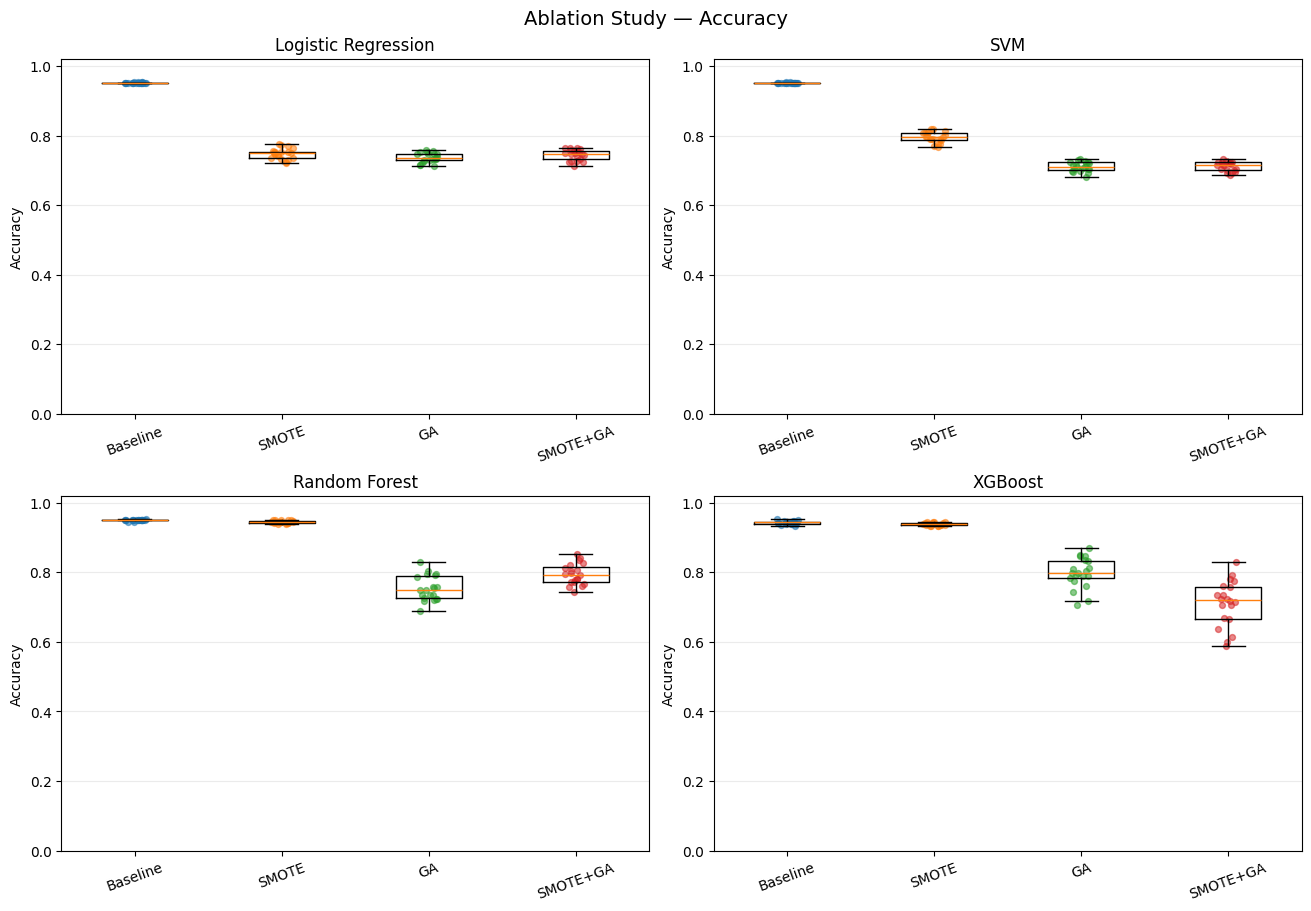

Grafik tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\figures_by_metric\ablation_accuracy.png


C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter o

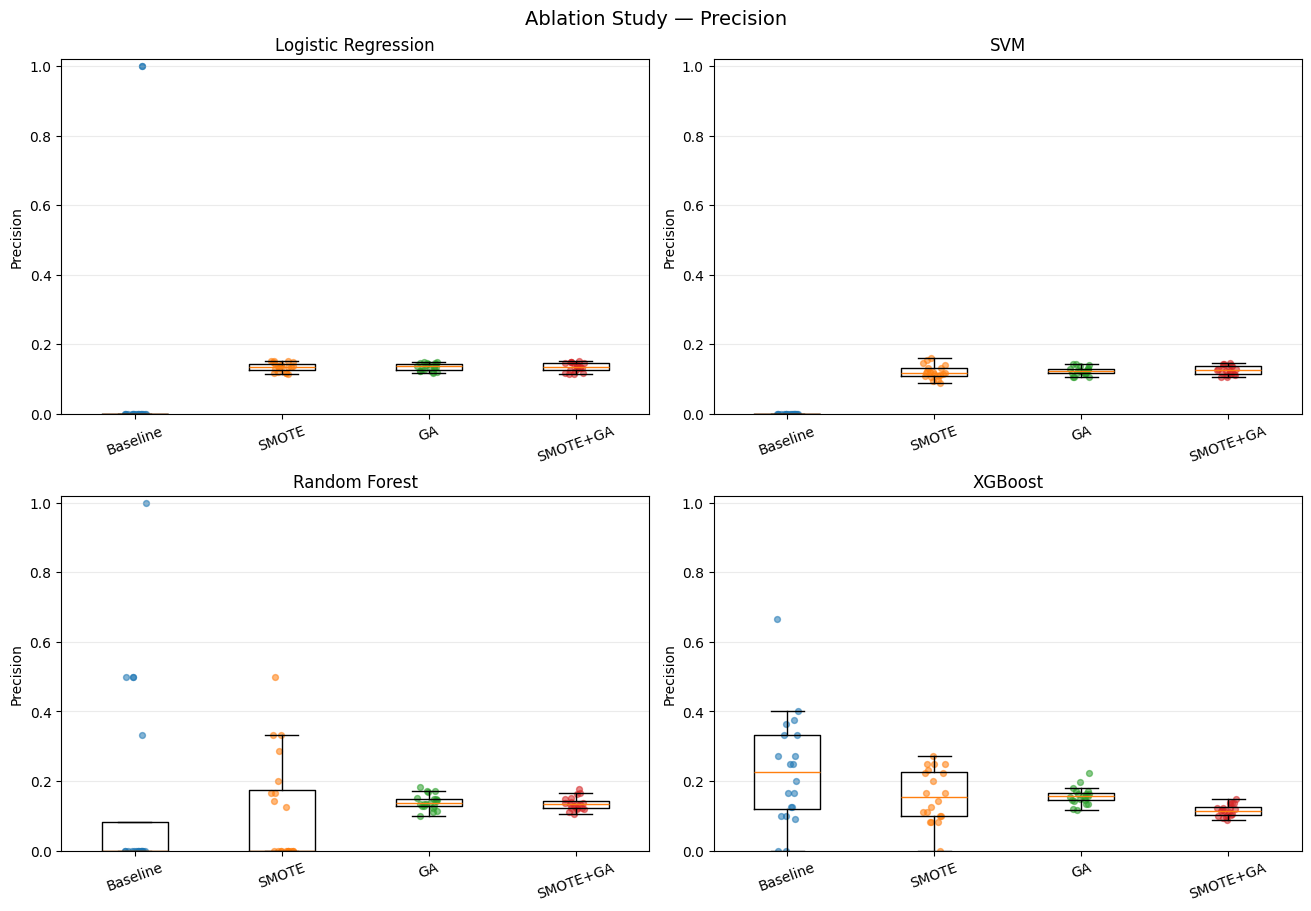

Grafik tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\figures_by_metric\ablation_precision.png


C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter o

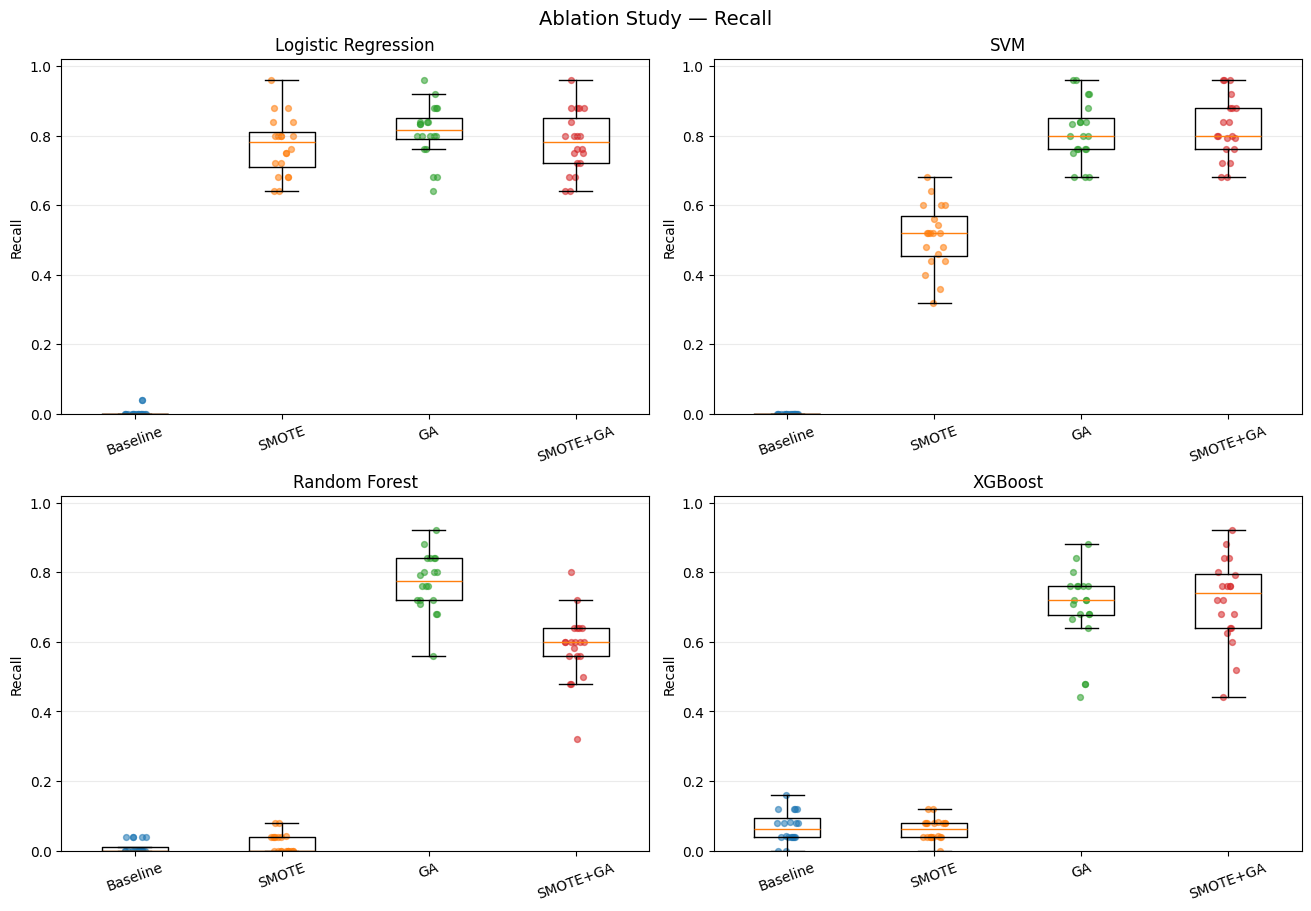

Grafik tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\figures_by_metric\ablation_recall.png


C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter o

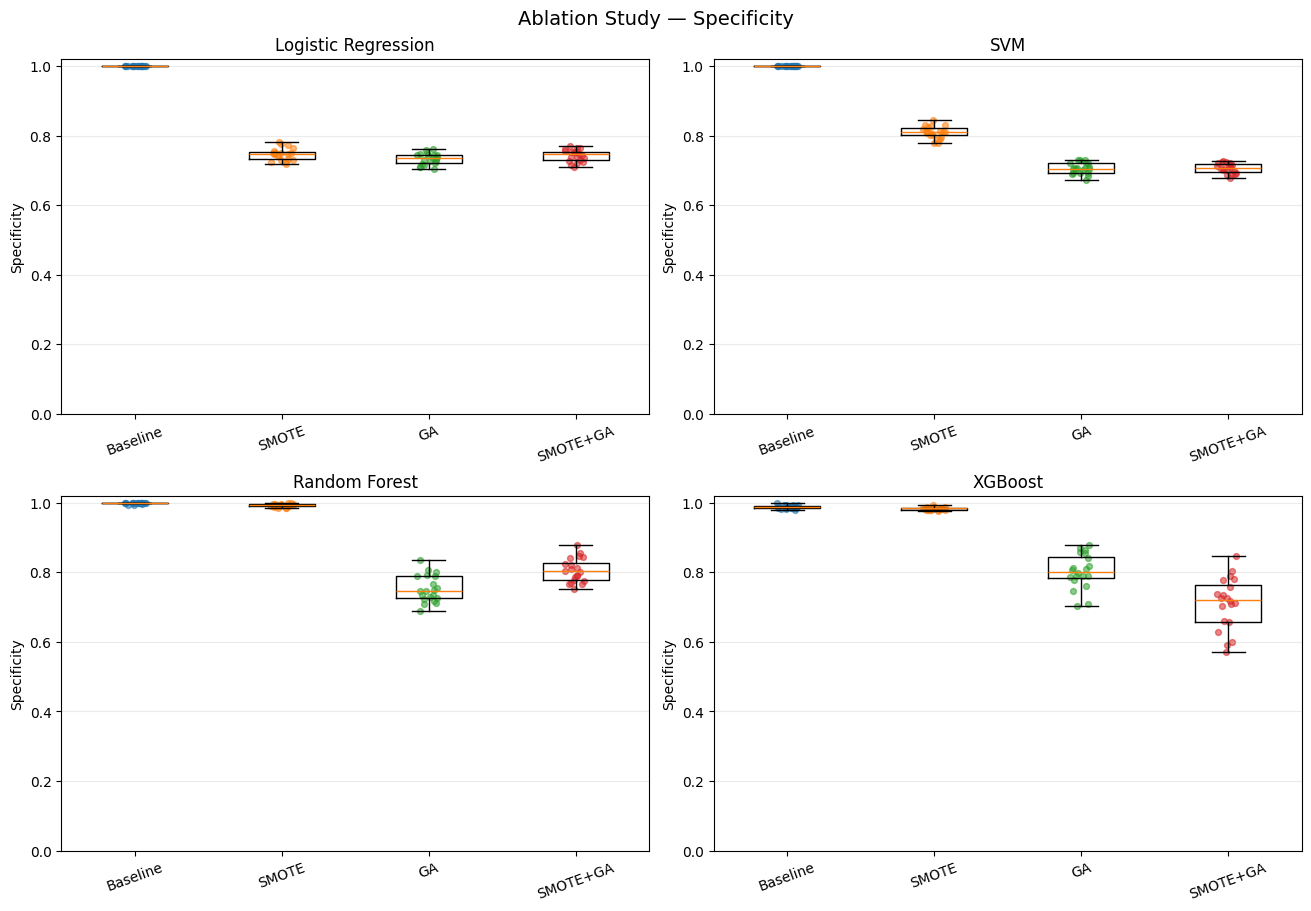

Grafik tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\figures_by_metric\ablation_specificity.png


C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter o

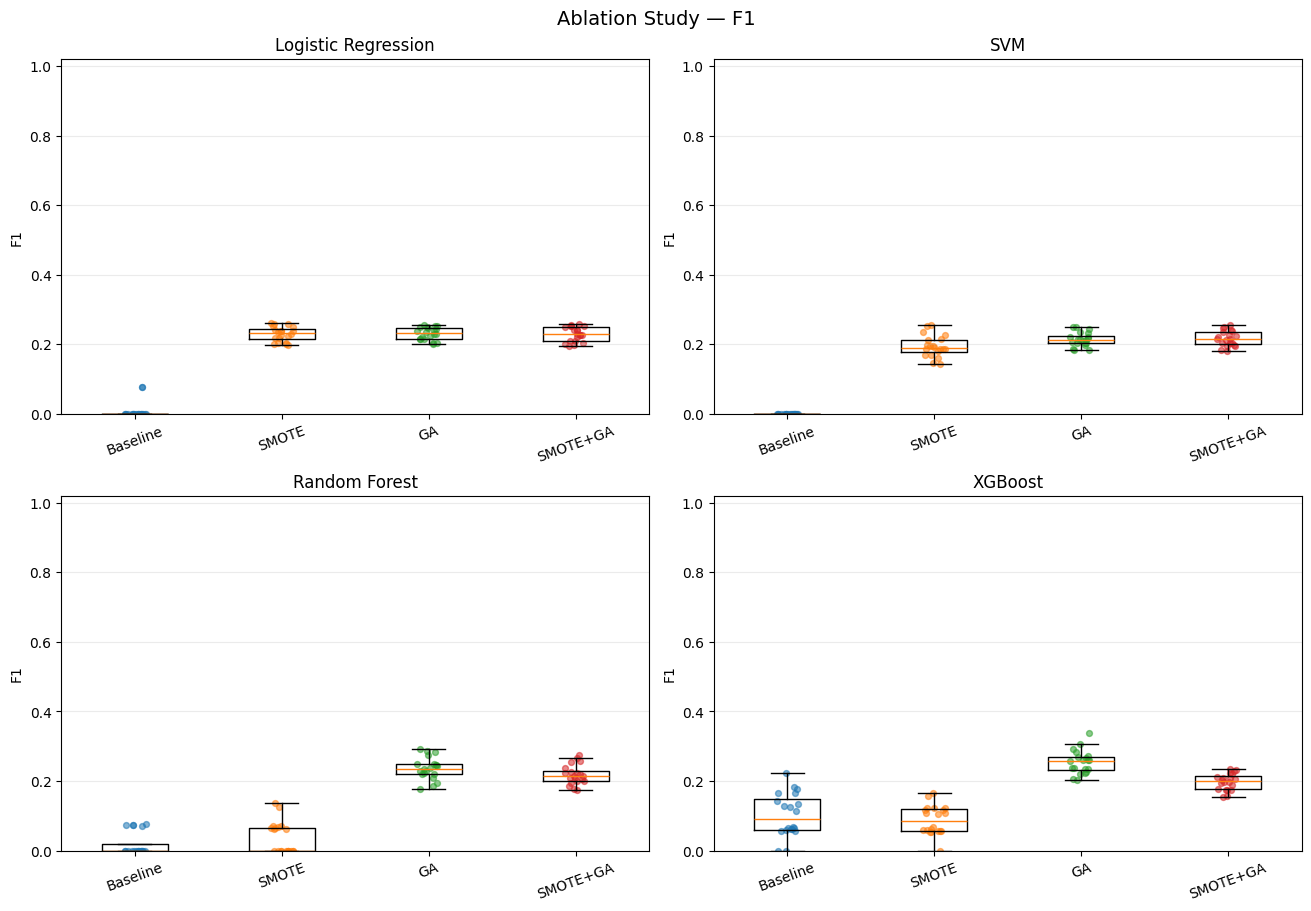

Grafik tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\figures_by_metric\ablation_f1.png


C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter o

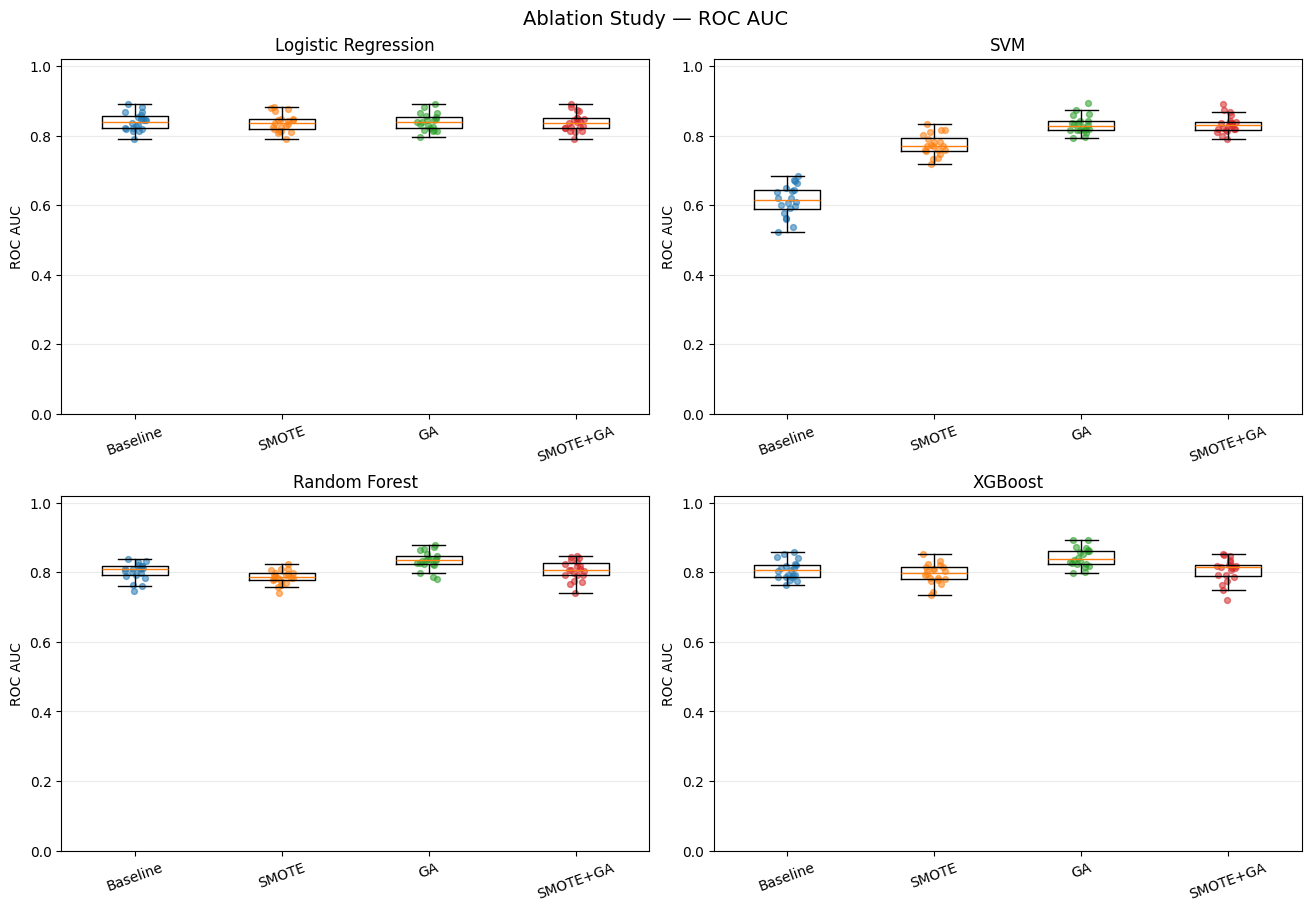

Grafik tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\figures_by_metric\ablation_roc_auc.png


C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter o

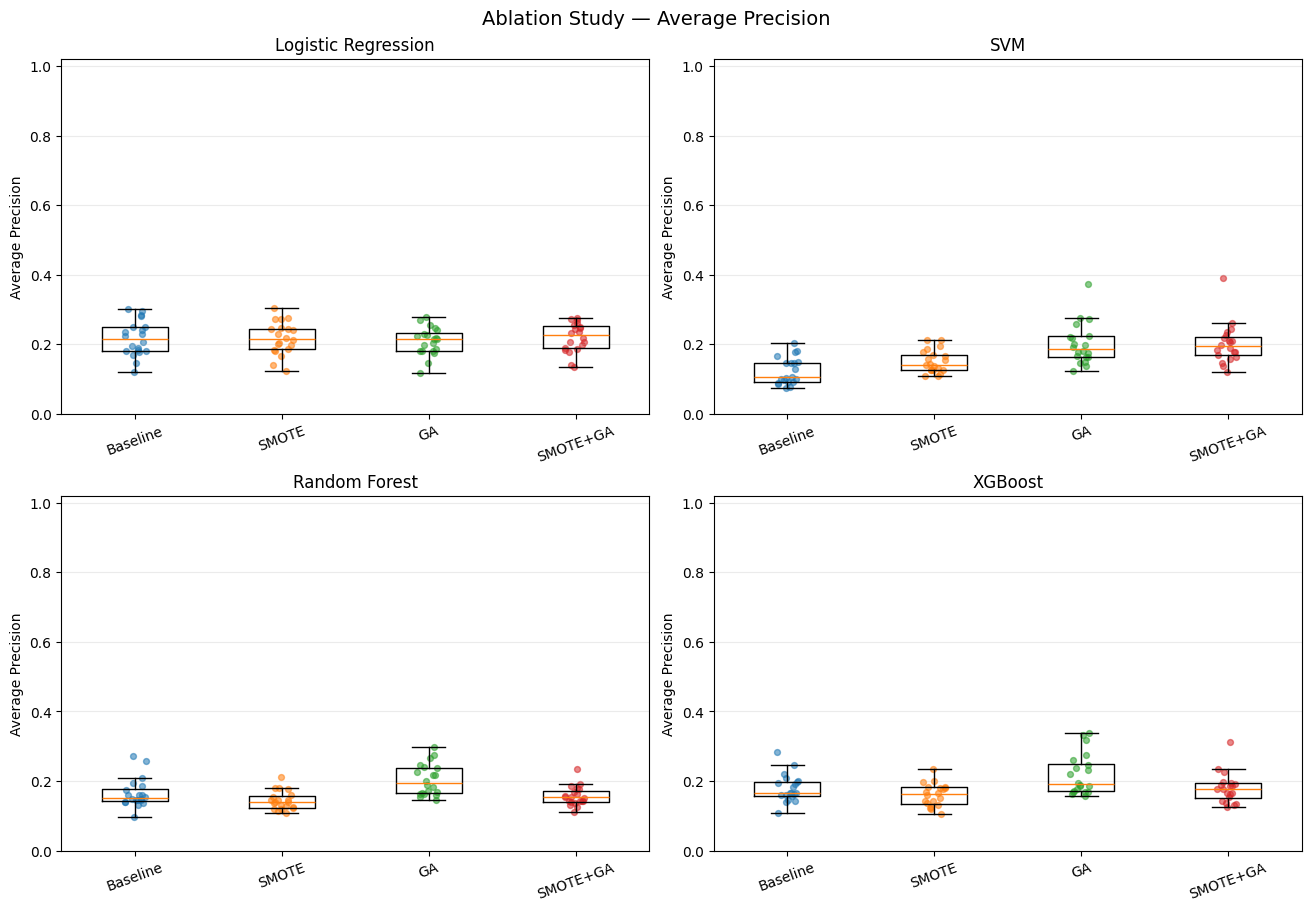

Grafik tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\figures_by_metric\ablation_average_precision.png


C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter o

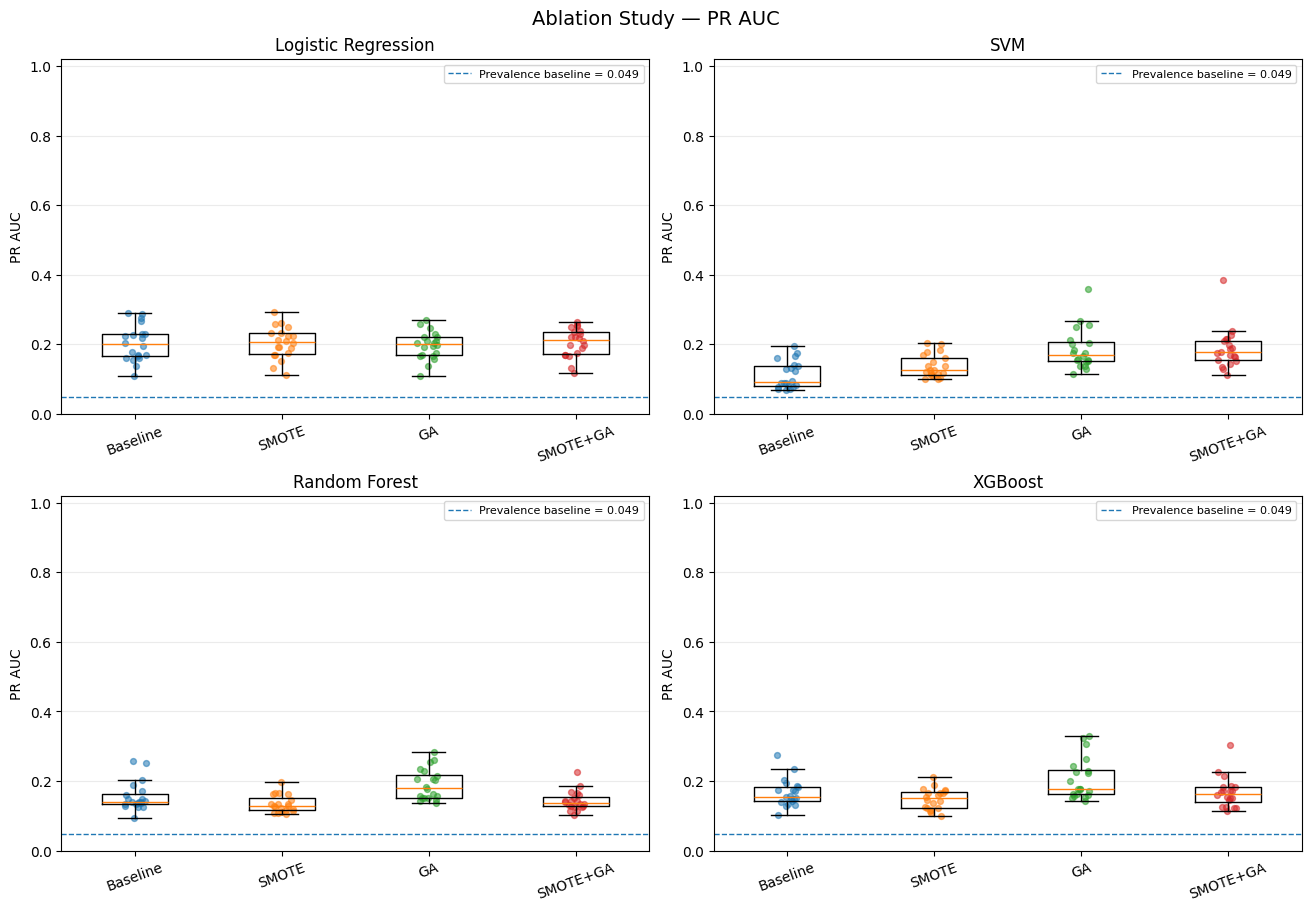

Grafik tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\figures_by_metric\ablation_pr_auc.png


C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter o

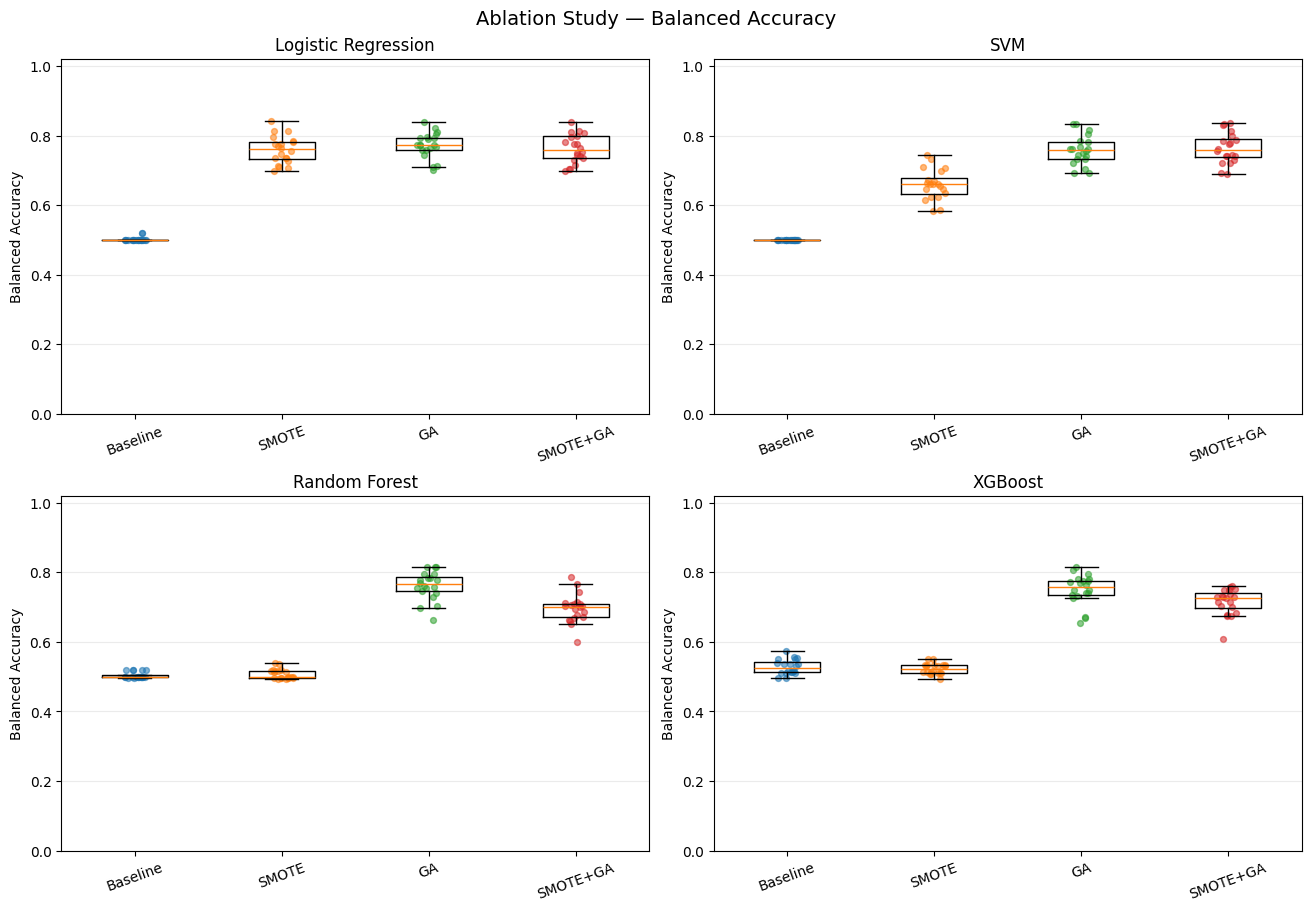

Grafik tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\figures_by_metric\ablation_balanced_accuracy.png


C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1083937873.py:32: MatplotlibDeprecationWarning: The 'labels' parameter o

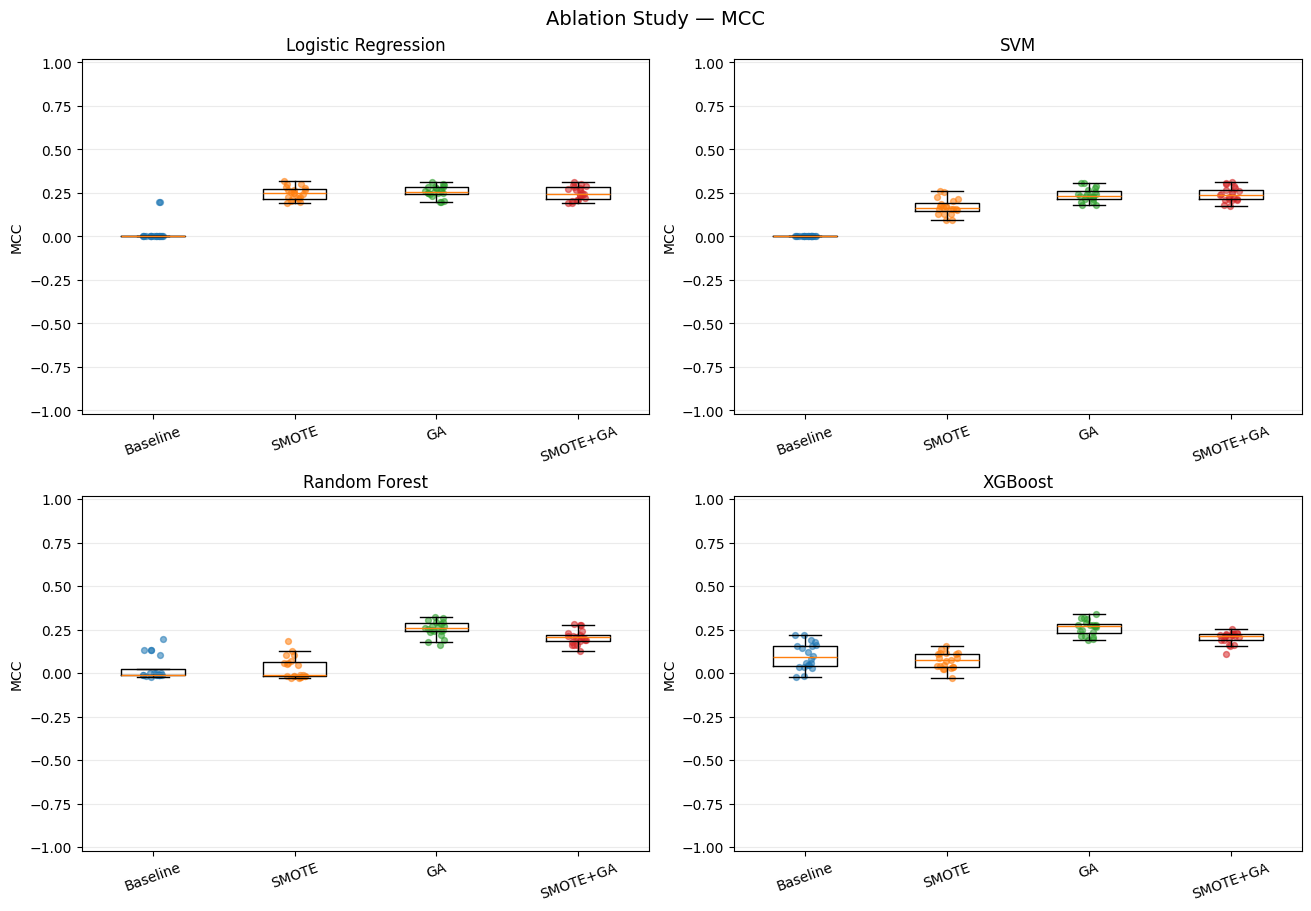

Grafik tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\figures_by_metric\ablation_mcc.png


In [4]:
# Plot performance metrics separately, one figure per metric.
PLOT_DIR = OUTPUT_DIR / "figures_by_metric"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

SCENARIO_COLORS = None  # gunakan warna default matplotlib
PR_AUC_PREVALENCE_BASELINE = 249 / 5110  # sekitar 4.87%; sesuaikan jika dataset berbeda

for metric in METRICS:
    if metric not in all_results.columns or not all_results[metric].notna().any():
        print(f"Skip {metric}: tidak tersedia.")
        continue

    fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
    axes = axes.flatten()

    for ax, model in zip(axes, MODELS):
        plot_data = []
        labels = []
        for scenario in SCENARIOS:
            vals = pd.to_numeric(
                all_results.loc[
                    (all_results["Model"] == model) &
                    (all_results["Scenario"] == scenario), metric
                ],
                errors="coerce"
            ).dropna().to_numpy()
            if len(vals):
                plot_data.append(vals)
                labels.append(scenario)

        if plot_data:
            ax.boxplot(plot_data, labels=labels, showfliers=False)
            rng = np.random.default_rng(42)
            for i, vals in enumerate(plot_data, start=1):
                jitter = rng.uniform(-0.08, 0.08, size=len(vals))
                ax.scatter(i + jitter, vals, alpha=0.55, s=18)
        ax.set_title(model)
        ax.set_ylabel(metric.replace("_", " "))
        ax.tick_params(axis="x", rotation=20)
        ax.grid(axis="y", alpha=0.25)

        if metric in ["Accuracy", "Precision", "Recall", "Specificity", "F1",
                      "ROC_AUC", "Average_Precision", "PR_AUC", "Balanced_Accuracy"]:
            ax.set_ylim(bottom=0, top=1.02)
        if metric == "MCC":
            ax.set_ylim(-1.02, 1.02)
        if metric == "PR_AUC":
            ax.axhline(
                PR_AUC_PREVALENCE_BASELINE,
                linestyle="--",
                linewidth=1,
                label=f"Prevalence baseline = {PR_AUC_PREVALENCE_BASELINE:.3f}"
            )
            ax.legend(fontsize=8)

    fig.suptitle(f"Ablation Study — {metric.replace('_', ' ')}", fontsize=14)
    out = PLOT_DIR / f"ablation_{metric.lower()}.png"
    fig.savefig(out, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Grafik tersimpan: {out}")

C:\Users\asus\AppData\Local\Temp\ipykernel_26556\68291913.py:153: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(top=0.78)


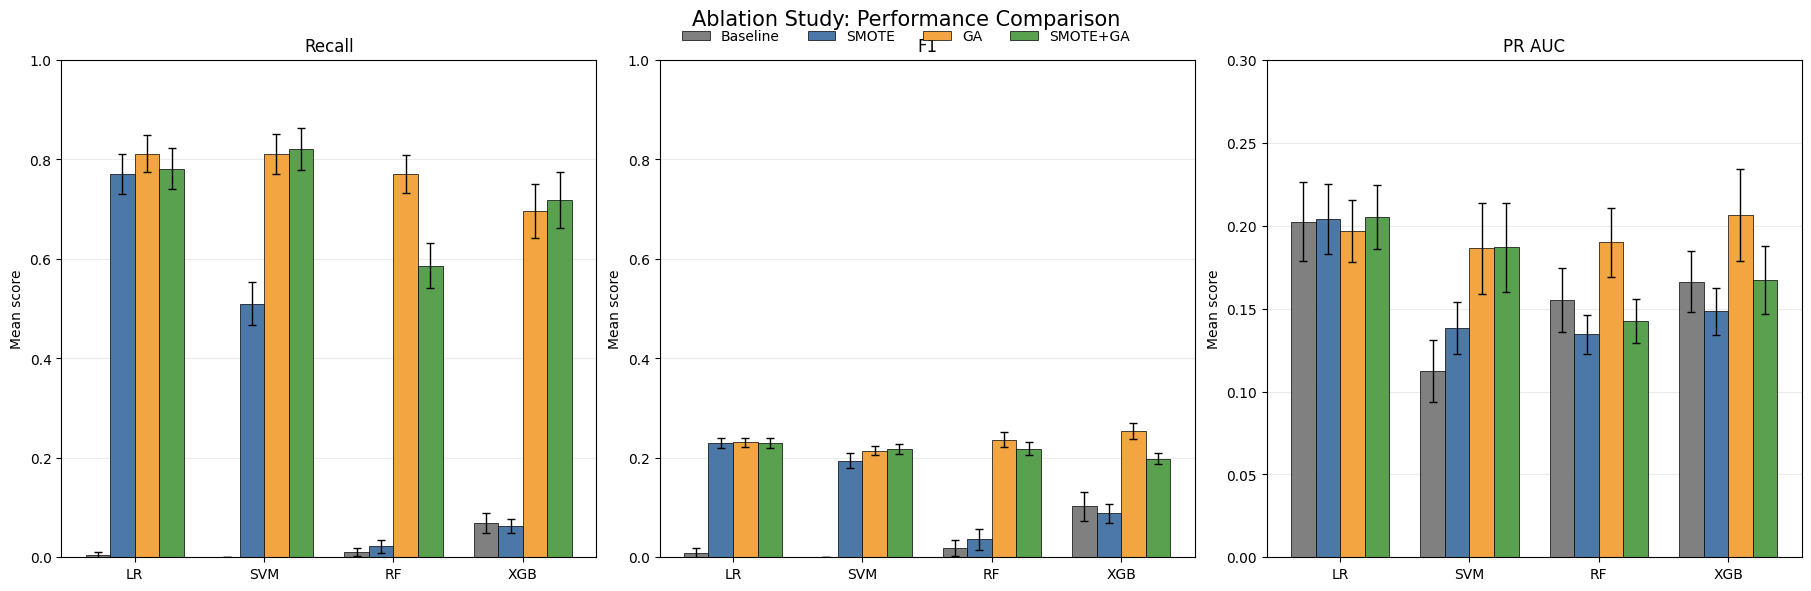

Grafik tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\grouped_bar_charts\ablation_grouped_bar_3_metrics.png


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t
from pathlib import Path

# =========================================================
# CONFIGURATION
# =========================================================
PLOT_DIR = OUTPUT_DIR / "grouped_bar_charts"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

PLOT_METRICS = ["Recall", "F1", "PR_AUC"]

# Consistent ordering across all panels
MODELS = ["Logistic Regression", "SVM", "Random Forest", "XGBoost"]
MODEL_LABELS = {
    "Logistic Regression": "LR",
    "SVM": "SVM",
    "Random Forest": "RF",
    "XGBoost": "XGB",
}

SCENARIOS = ["Baseline", "SMOTE", "GA", "SMOTE+GA"]

# Consistent colors across all panels
SCENARIO_COLORS = {
    "Baseline": "#808080",
    "SMOTE": "#4C78A8",
    "GA": "#F2A541",
    "SMOTE+GA": "#59A14F",
}

# Y-axis upper limits. Adjust after checking the actual data.
Y_AXIS_LIMITS = {
    "Recall": (0, 1.0),
    "F1": (0, 1.0),
    "PR_AUC": (0, 0.30),
}

# =========================================================
# HELPER: MEAN AND 95% T-BASED CONFIDENCE INTERVAL
# =========================================================
def calculate_ci95(values):
    values = pd.to_numeric(
        pd.Series(values), errors="coerce"
    ).dropna().to_numpy(dtype=float)

    n = len(values)

    if n == 0:
        return np.nan, np.nan, np.nan

    mean = np.mean(values)

    if n < 2:
        return mean, np.nan, np.nan

    sd = np.std(values, ddof=1)
    se = sd / np.sqrt(n)
    margin = t.ppf(0.975, df=n - 1) * se

    return mean, mean - margin, mean + margin


# =========================================================
# GROUPED BAR CHART: THREE PANELS
# =========================================================
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5.8),
    constrained_layout=True
)

x = np.arange(len(MODELS))
bar_width = 0.19
offsets = (
    np.arange(len(SCENARIOS)) - (len(SCENARIOS) - 1) / 2
) * bar_width

for ax, metric in zip(axes, PLOT_METRICS):

    for scenario_idx, scenario in enumerate(SCENARIOS):
        means = []
        ci_lowers = []
        ci_uppers = []

        for model in MODELS:
            values = all_results.loc[
                (all_results["Model"] == model) &
                (all_results["Scenario"] == scenario),
                metric
            ]

            mean, lower, upper = calculate_ci95(values)

            means.append(mean)
            ci_lowers.append(lower)
            ci_uppers.append(upper)

        means = np.asarray(means, dtype=float)
        ci_lowers = np.asarray(ci_lowers, dtype=float)
        ci_uppers = np.asarray(ci_uppers, dtype=float)

        # Asymmetric error bars for the 95% CI
        lower_error = np.maximum(0, means - ci_lowers)
        upper_error = np.maximum(0, ci_uppers - means)

        valid = np.isfinite(means)
        errors = np.vstack([
            np.where(np.isfinite(lower_error), lower_error, 0),
            np.where(np.isfinite(upper_error), upper_error, 0),
        ])

        ax.bar(
            x[valid] + offsets[scenario_idx],
            means[valid],
            width=bar_width,
            label=scenario,
            color=SCENARIO_COLORS[scenario],
            edgecolor="black",
            linewidth=0.5,
            yerr=errors[:, valid],
            capsize=3,
            error_kw={"elinewidth": 1, "capthick": 1},
        )

    ax.set_title(metric.replace("_", " "), fontsize=12)
    ax.set_ylabel("Mean score")
    ax.set_xticks(x)
    ax.set_xticklabels([MODEL_LABELS[m] for m in MODELS])
    ax.set_ylim(*Y_AXIS_LIMITS.get(metric, (0, 1.0)))
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

fig.suptitle(
    "Ablation Study: Performance Comparison",
    fontsize=15
)

# One shared legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.98),
    ncol=4,
    frameon=False
)

# Leave room for the shared legend and title
fig.subplots_adjust(top=0.78)

out = PLOT_DIR / "ablation_grouped_bar_3_metrics.png"
fig.savefig(out, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Grafik tersimpan: {out}")

## 4. Confusion-matrix summary and false negatives

False negatives for the stroke class are important. If fold-level files contain TN, FP, FN, and TP, this section sums these counts across available folds for each model and scenario. **Counts summed across repeated cross-validation folds are not counts of unique patients**, because observations may appear in test folds in different repeats.

In [6]:
CM_COLS = ["TN", "FP", "FN", "TP"]
if all(col in all_results.columns for col in CM_COLS):
    cm_rows = []
    for model in MODELS:
        for scenario in SCENARIOS:
            sub = all_results[
                (all_results["Model"] == model) &
                (all_results["Scenario"] == scenario)
            ]
            row = {"Model": model, "Scenario": scenario, "N_fold_rows": len(sub)}
            for col in CM_COLS:
                row[f"Sum_{col}"] = pd.to_numeric(sub[col], errors="coerce").sum(min_count=1)
            cm_rows.append(row)
    confusion_summary = pd.DataFrame(cm_rows)
    print("=== JUMLAH CONFUSION-MATRIX COUNTS PER MODEL × SKENARIO ===")
    display(confusion_summary)
    cm_path = OUTPUT_DIR / "ablation_confusion_matrix_counts_by_model_scenario_new.csv"
    confusion_summary.to_csv(cm_path, index=False)
    print(f"CSV tersimpan: {cm_path}")
else:
    print("Tidak semua kolom TN/FP/FN/TP tersedia pada data gabungan. Periksa loader sumber.")

=== JUMLAH CONFUSION-MATRIX COUNTS PER MODEL × SKENARIO ===


,Model,Scenario,N_fold_rows,Sum_TN,Sum_FP,Sum_FN,Sum_TP
0,Logistic Regression,Baseline,20,9722.0,0.0,496.0,2.0
1,Logistic Regression,SMOTE,20,7261.0,2461.0,114.0,384.0
2,Logistic Regression,GA,20,7127.0,2595.0,94.0,404.0
3,Logistic Regression,SMOTE+GA,20,7223.0,2499.0,109.0,389.0
4,SVM,Baseline,20,9722.0,0.0,498.0,0.0
5,SVM,SMOTE,20,7869.0,1853.0,244.0,254.0
6,SVM,GA,20,6859.0,2863.0,94.0,404.0
7,SVM,SMOTE+GA,20,6865.0,2857.0,89.0,409.0
8,Random Forest,Baseline,20,9701.0,21.0,493.0,5.0
9,Random Forest,SMOTE,20,9644.0,78.0,487.0,11.0


CSV tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\ablation_confusion_matrix_counts_by_model_scenario_new.csv


## 5. Runtime summary

Runtime is summarized separately because timer definitions may differ across scenarios. Before making efficiency comparisons, verify that the runtime columns in the source files measure comparable processes.

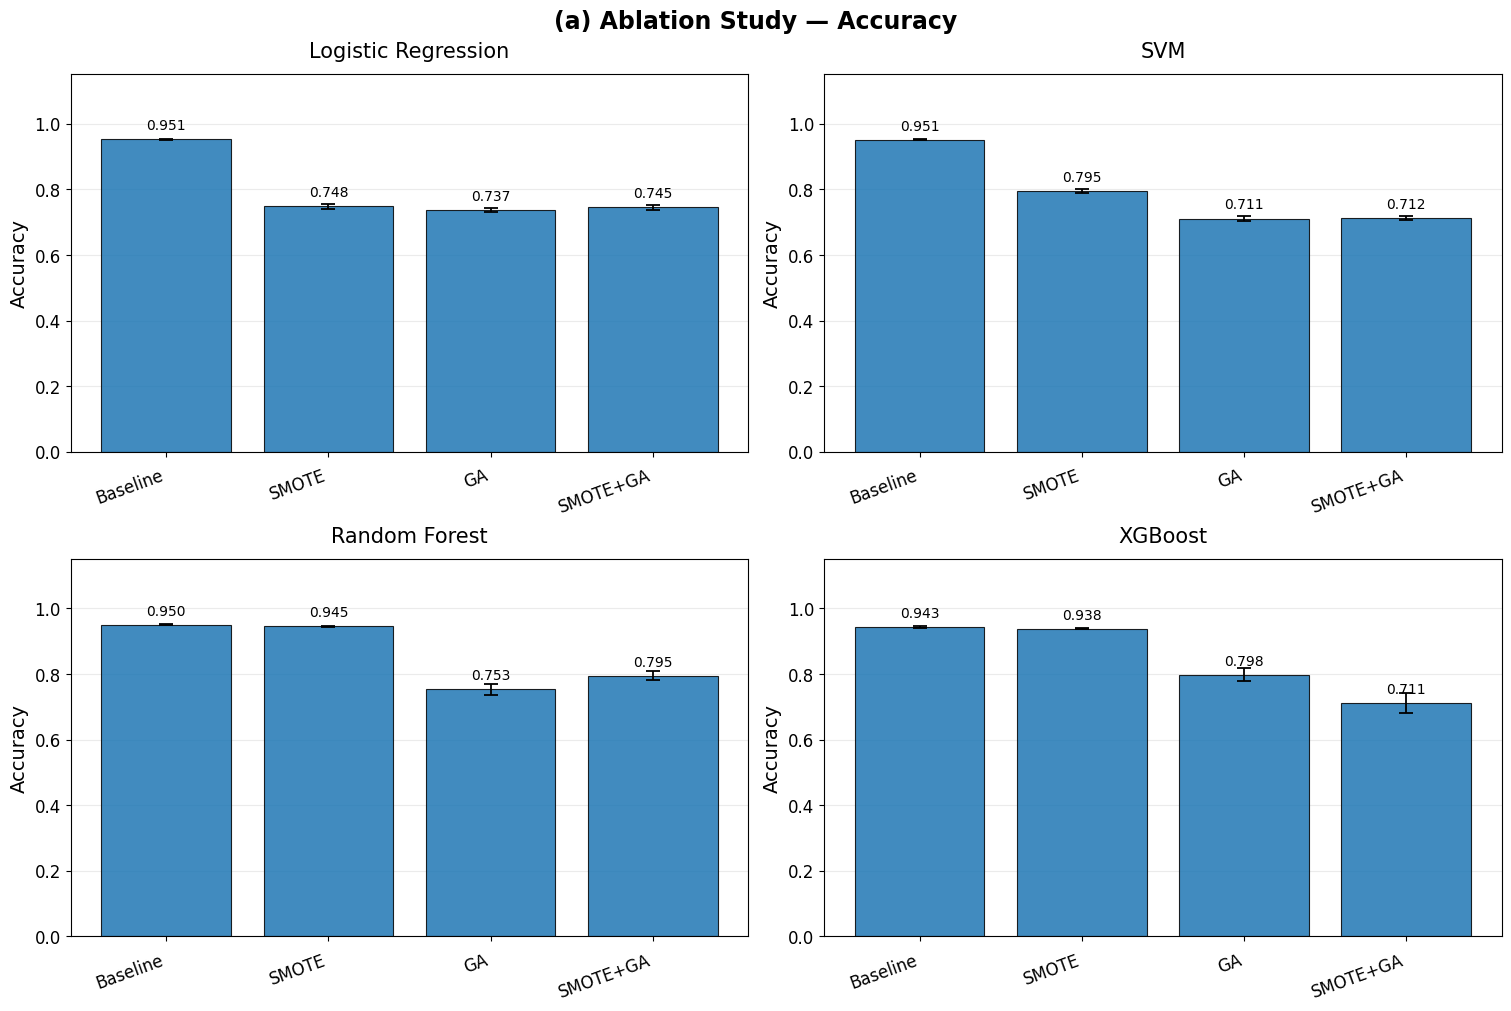

Grafik tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\bar_charts_by_metric\ablation_bar_accuracy.png


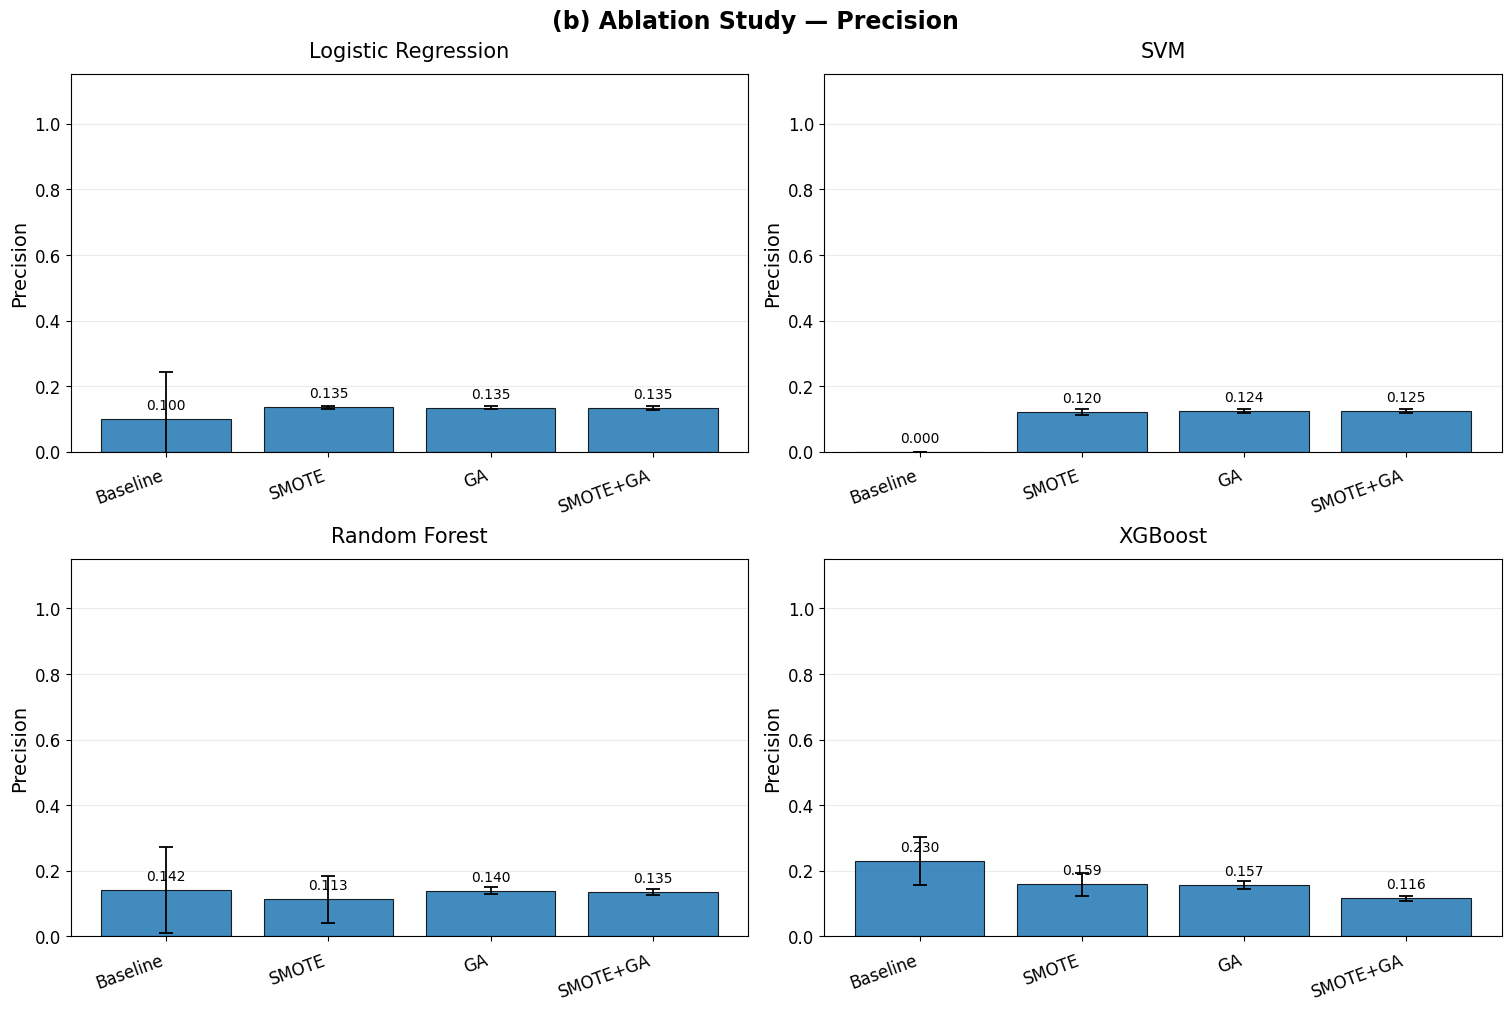

Grafik tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\bar_charts_by_metric\ablation_bar_precision.png


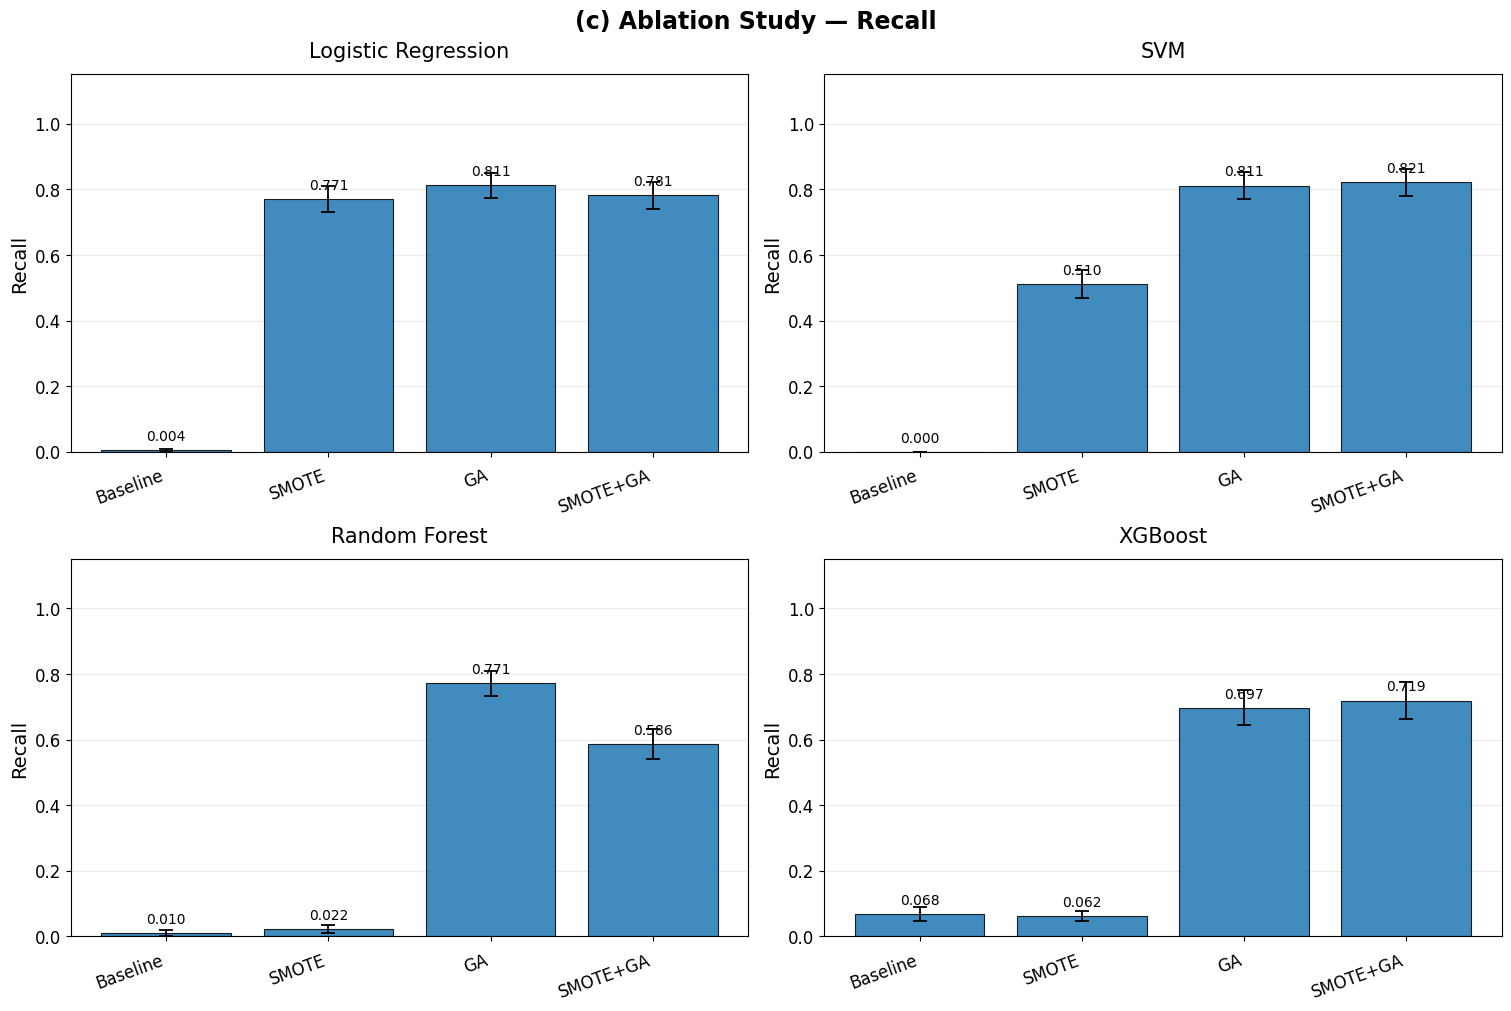

Grafik tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\bar_charts_by_metric\ablation_bar_recall.png


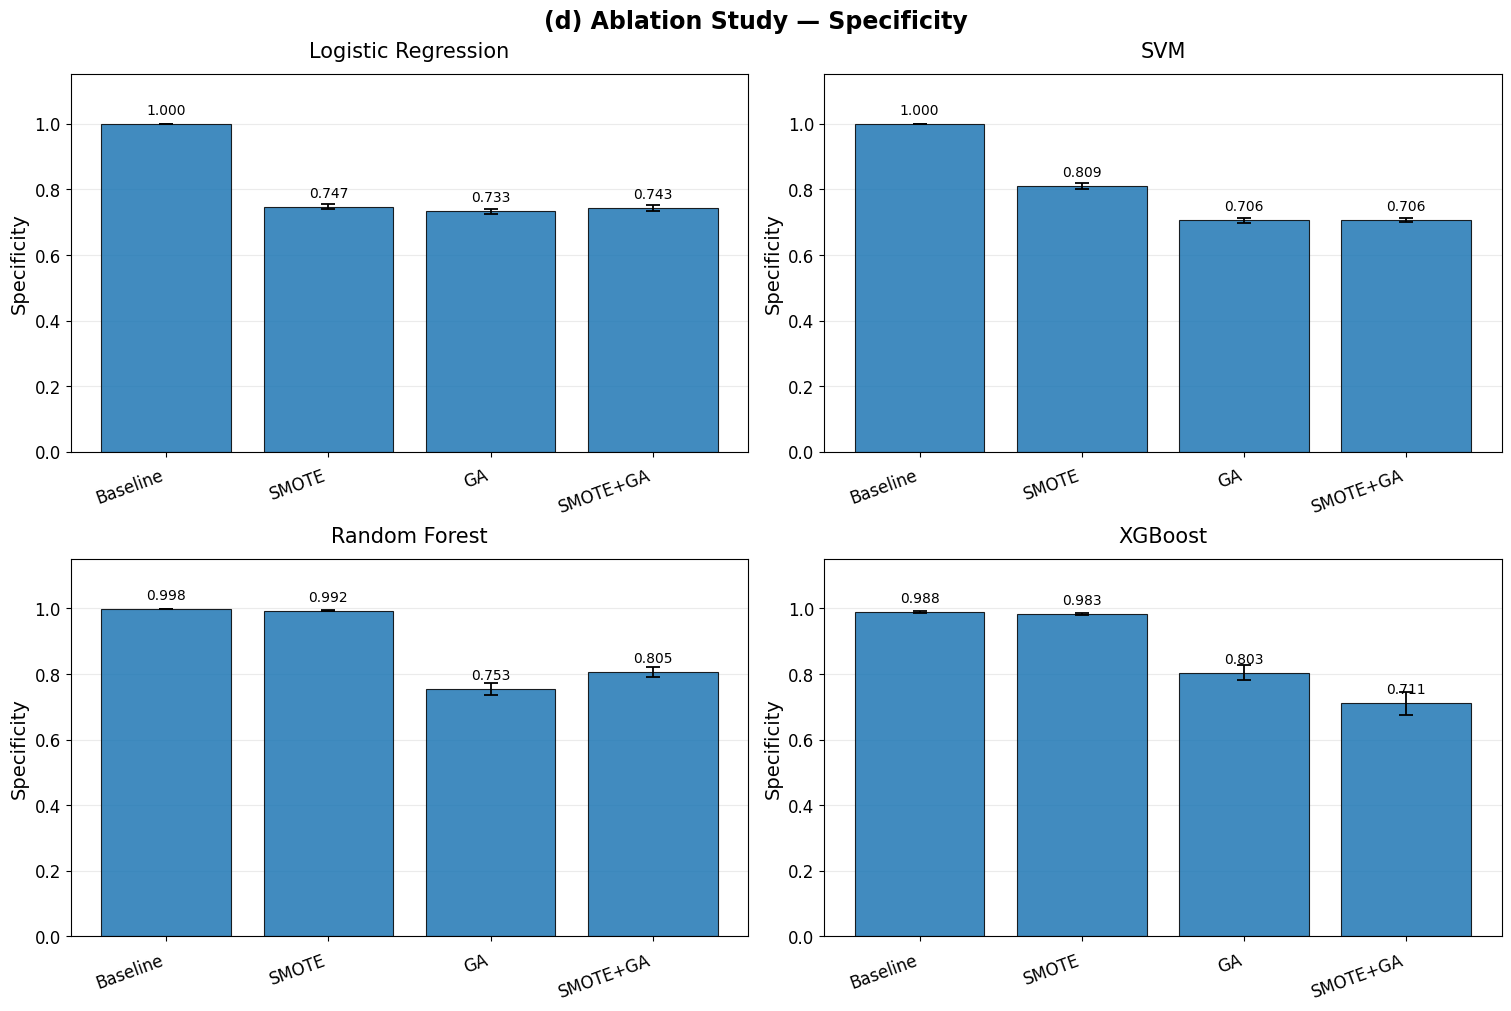

Grafik tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\bar_charts_by_metric\ablation_bar_specificity.png


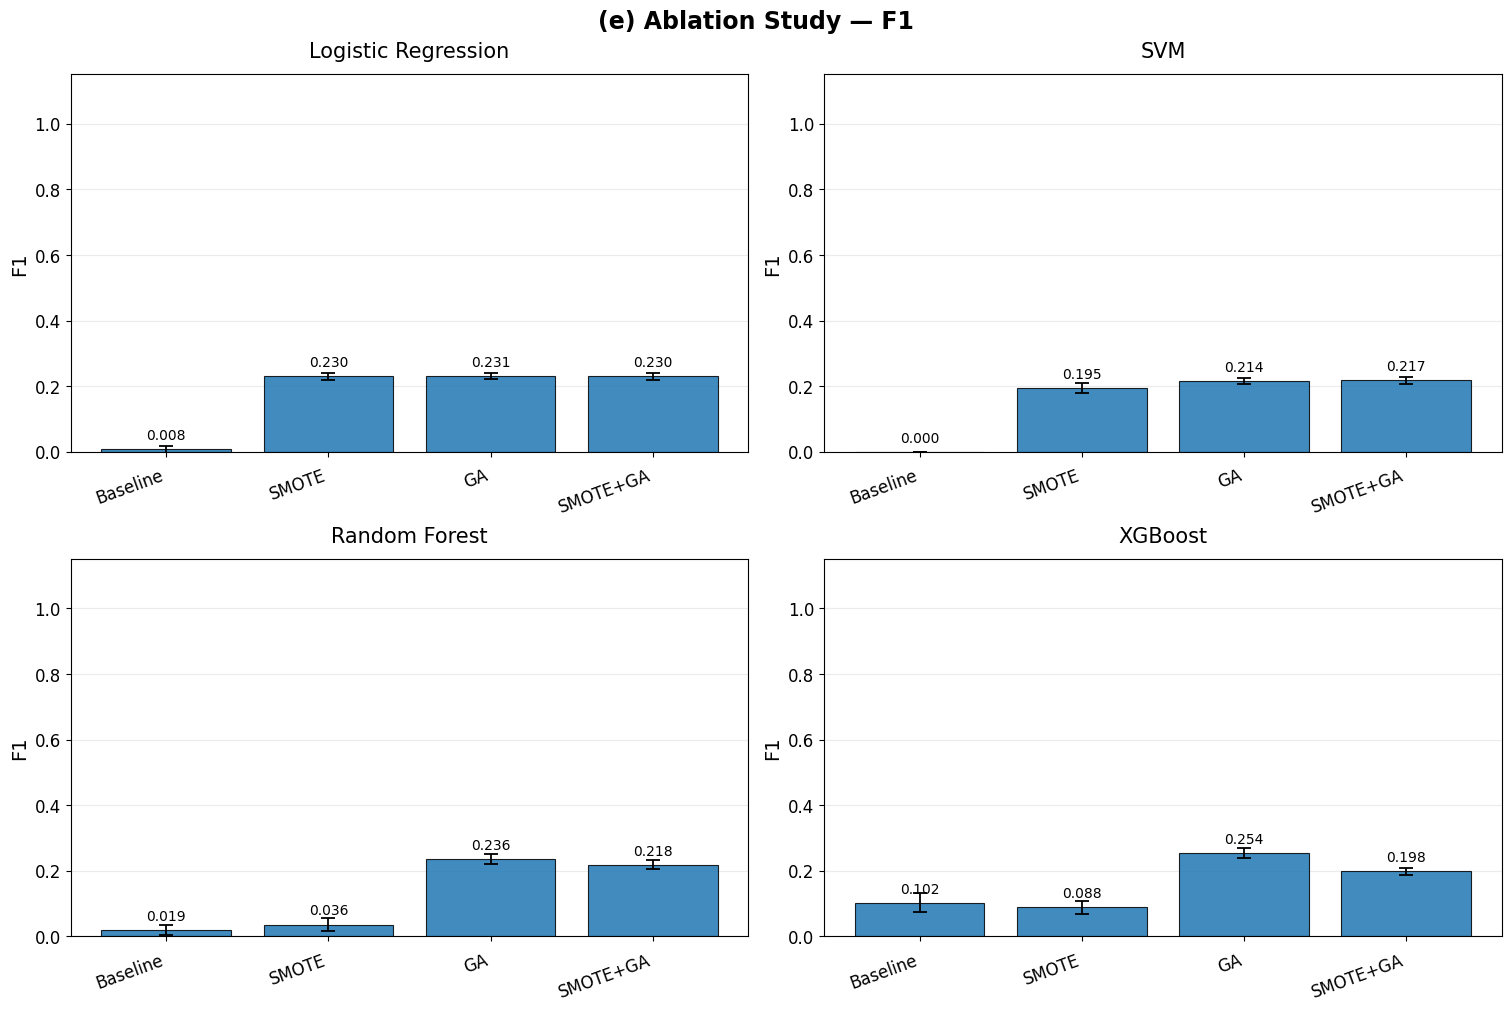

Grafik tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\bar_charts_by_metric\ablation_bar_f1.png


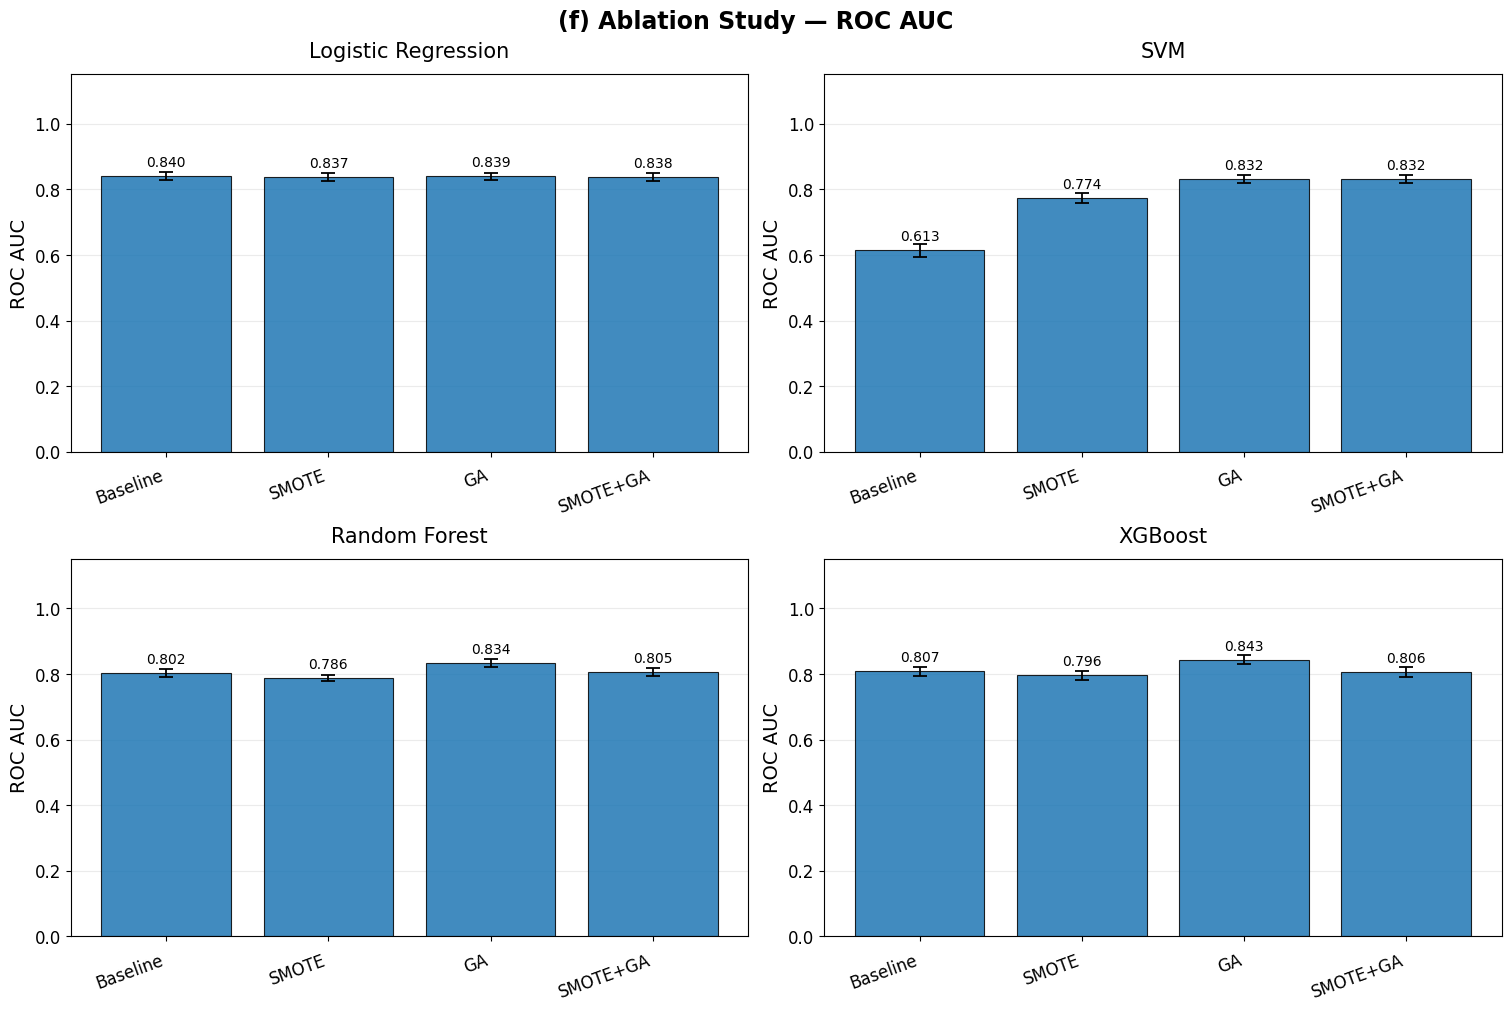

Grafik tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\bar_charts_by_metric\ablation_bar_roc_auc.png


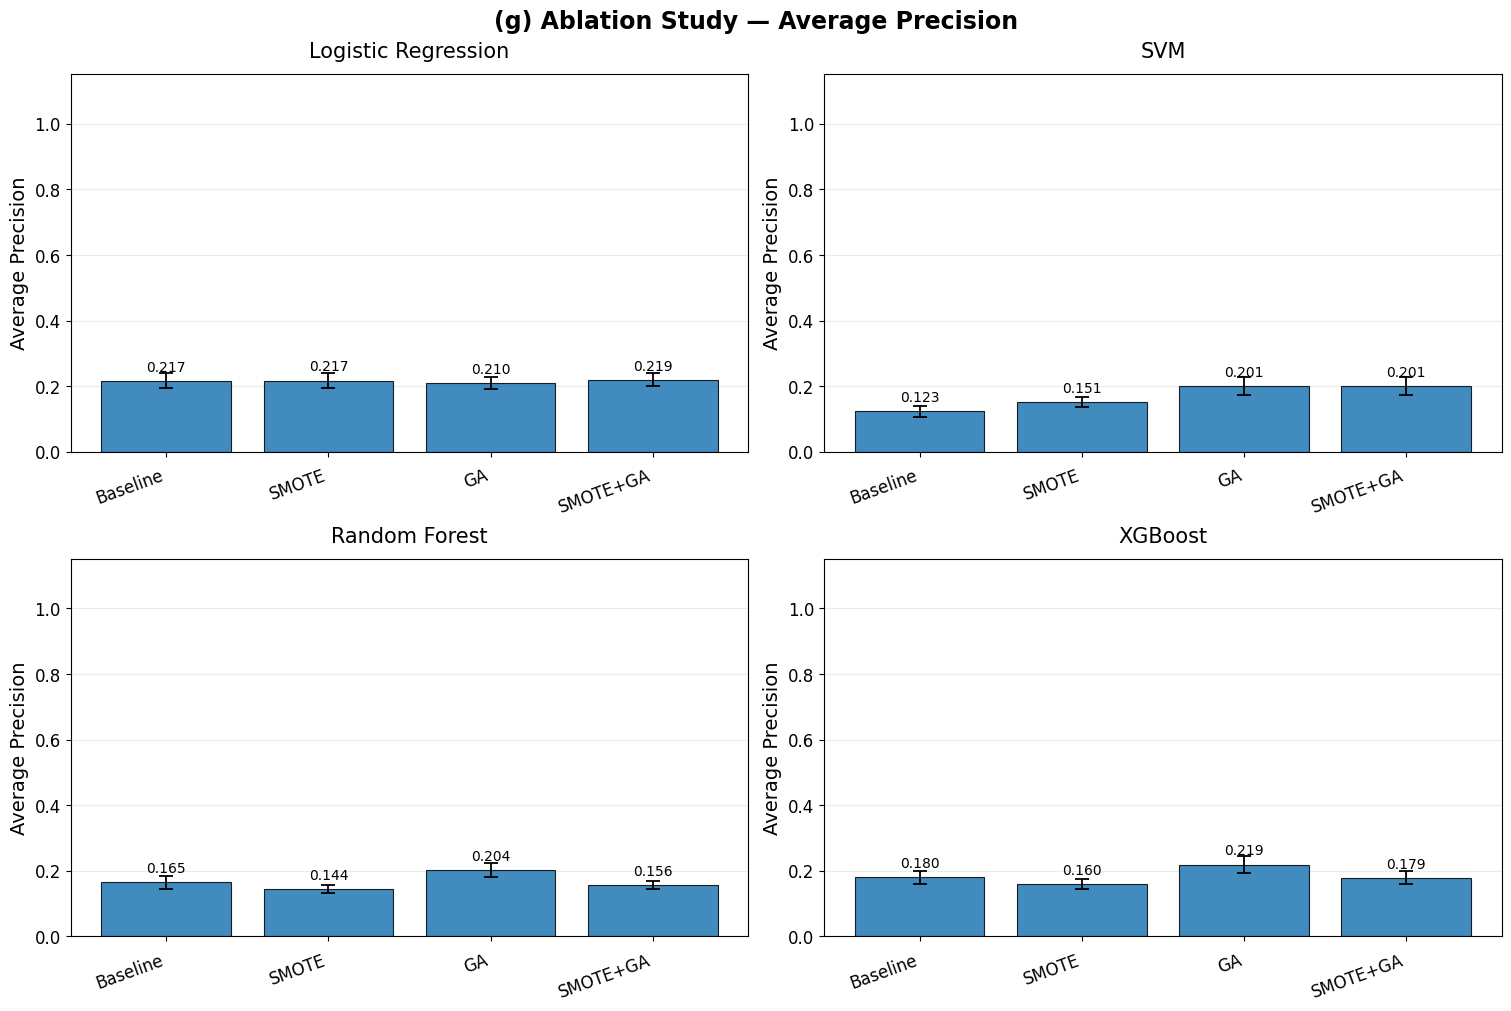

Grafik tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\bar_charts_by_metric\ablation_bar_average_precision.png


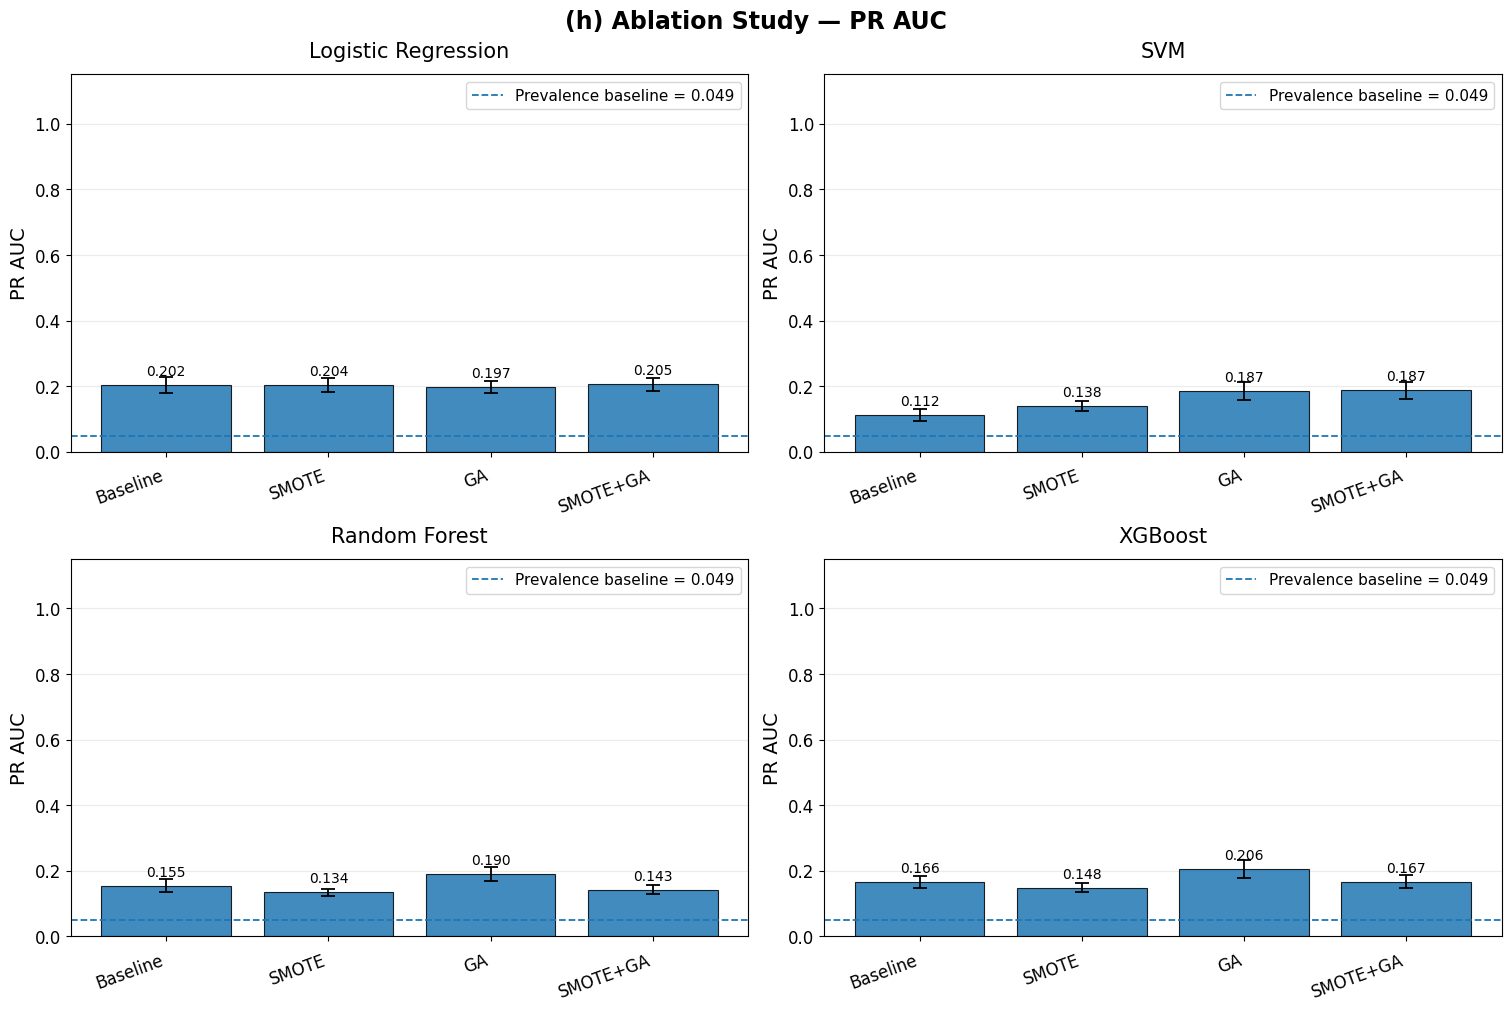

Grafik tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\bar_charts_by_metric\ablation_bar_pr_auc.png


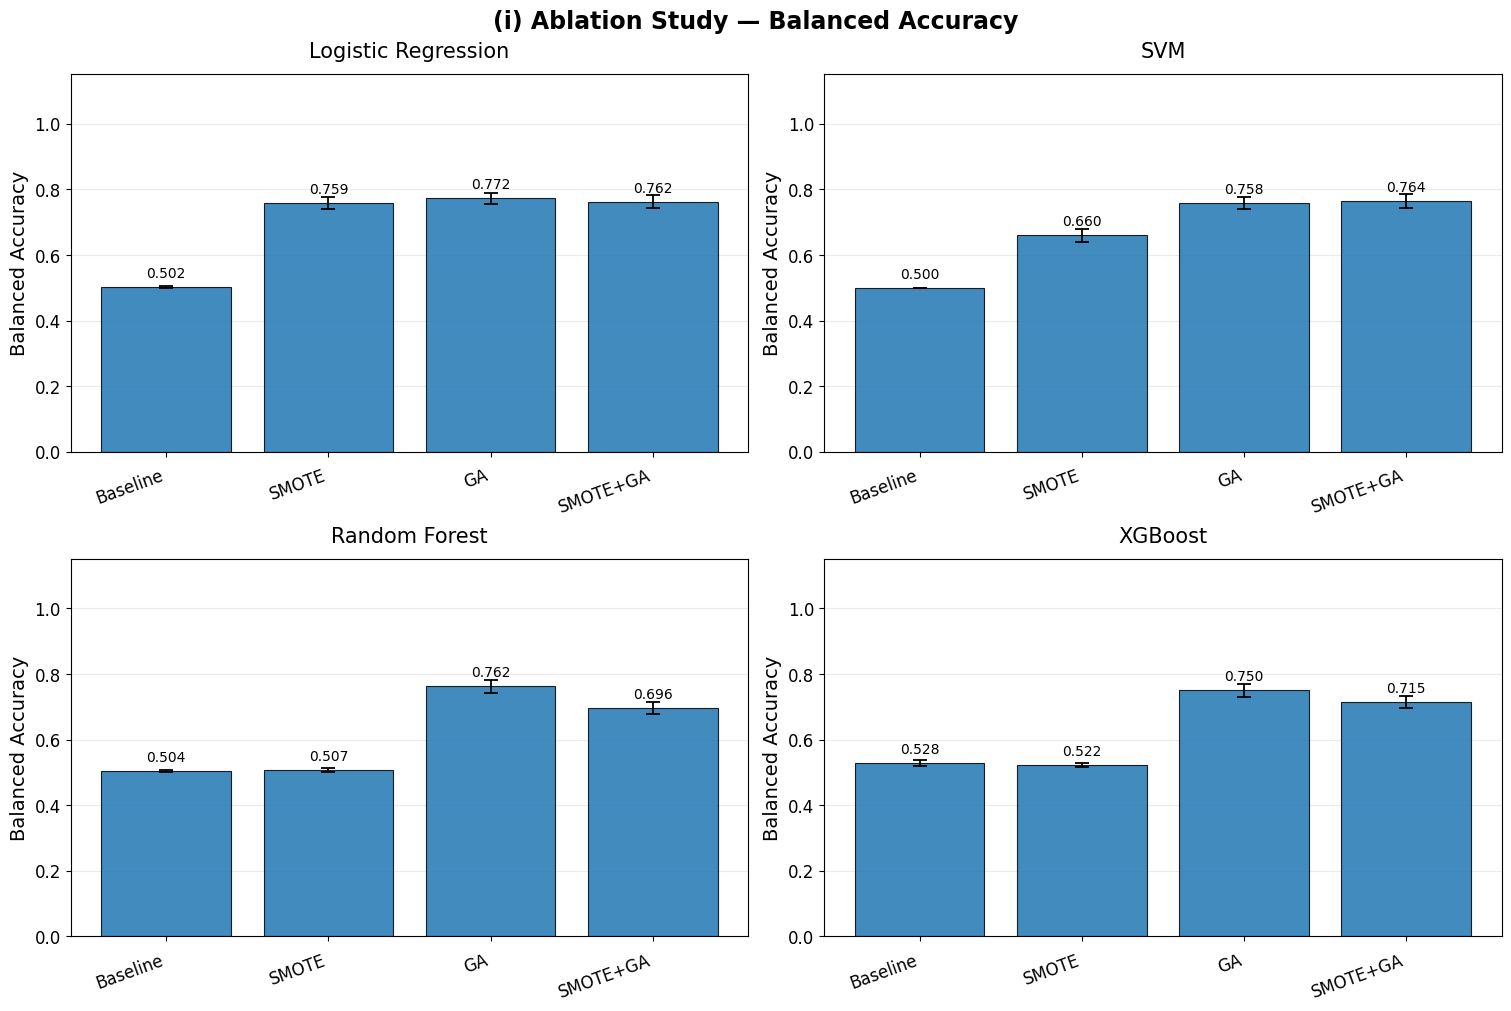

Grafik tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\bar_charts_by_metric\ablation_bar_balanced_accuracy.png


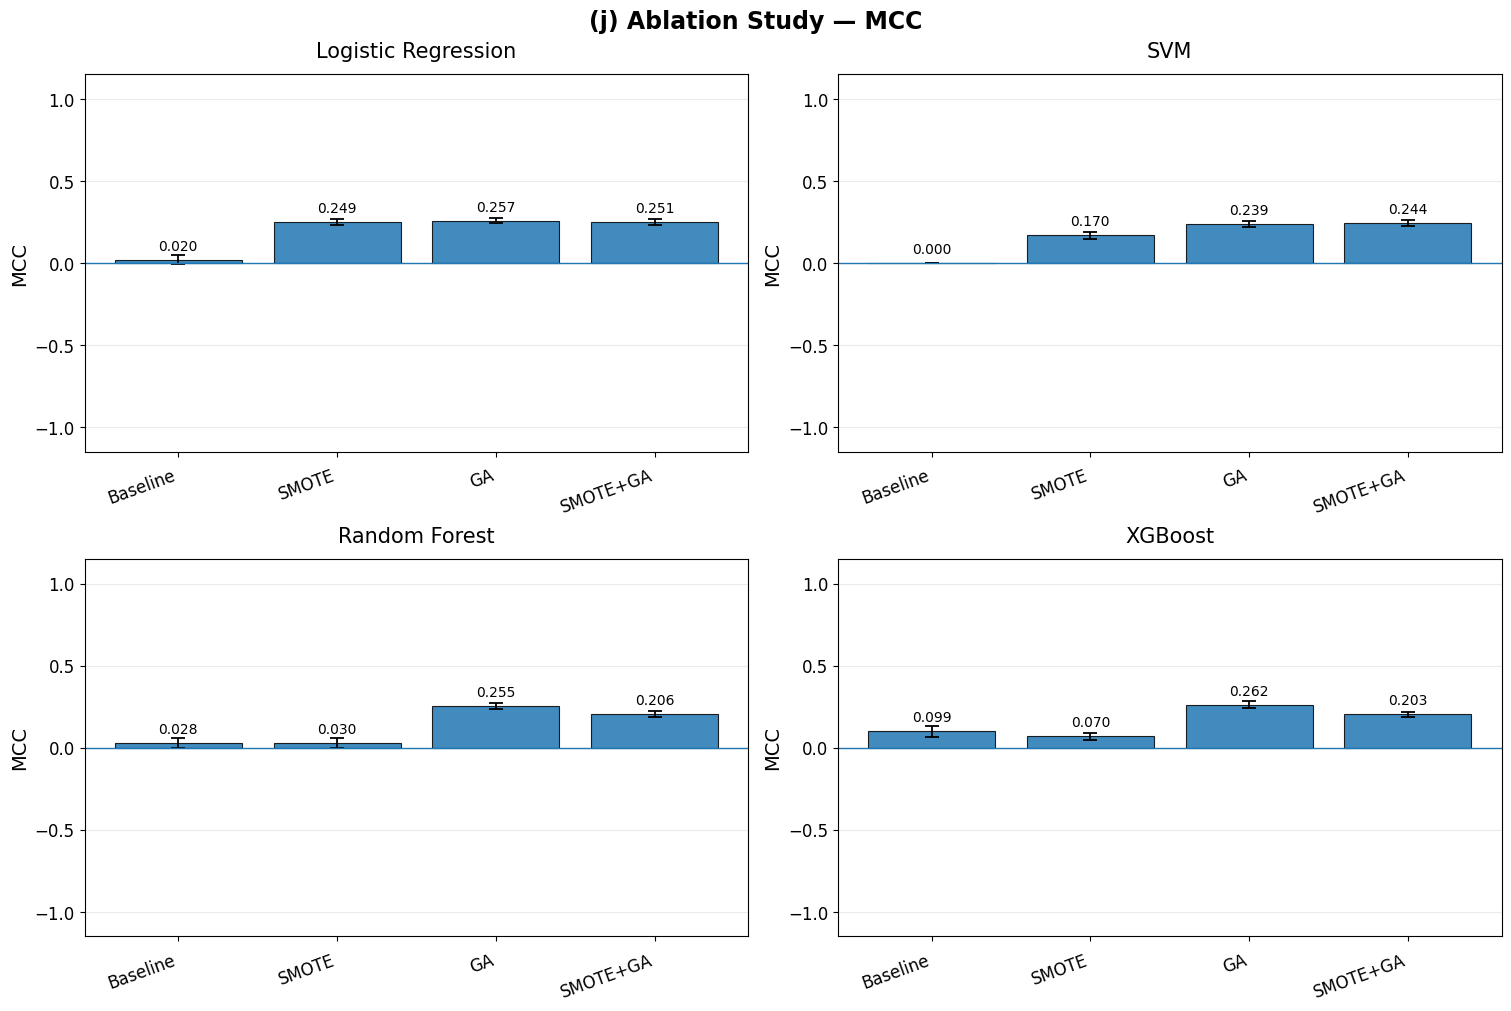

Grafik tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\bar_charts_by_metric\ablation_bar_mcc.png


In [7]:
# Bar chart performance metrics separately, one figure per metric.
PLOT_DIR = OUTPUT_DIR / "bar_charts_by_metric"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

PR_AUC_PREVALENCE_BASELINE = 249 / 5110

# Panel labels follow the metric order.
PANEL_LABELS = {
    metric: f"({chr(97 + i)})"
    for i, metric in enumerate(METRICS)
}

# Font configuration
TITLE_FONT = 17
SUBTITLE_FONT = 15
LABEL_FONT = 14
TICK_FONT = 12
VALUE_FONT = 10
LEGEND_FONT = 11


def calculate_ci95(values):
    """Return mean, lower CI, upper CI, and sample size."""
    values = pd.to_numeric(
        pd.Series(values), errors="coerce"
    ).dropna().to_numpy(dtype=float)

    n = len(values)

    if n == 0:
        return np.nan, np.nan, np.nan, 0

    mean_value = np.mean(values)

    if n < 2:
        return mean_value, np.nan, np.nan, n

    std_value = np.std(values, ddof=1)
    standard_error = std_value / np.sqrt(n)
    t_critical = t.ppf(0.975, df=n - 1)
    margin_error = t_critical * standard_error

    return (
        mean_value,
        mean_value - margin_error,
        mean_value + margin_error,
        n
    )


for metric in METRICS:
    if metric not in all_results.columns or not all_results[metric].notna().any():
        print(f"Skip {metric}: tidak tersedia.")
        continue

    fig, axes = plt.subplots(
        2, 2,
        figsize=(15, 10),
        constrained_layout=True
    )
    axes = axes.flatten()

    for ax, model in zip(axes, MODELS):
        means = []
        lower_errors = []
        upper_errors = []
        labels = []

        for scenario in SCENARIOS:
            vals = pd.to_numeric(
                all_results.loc[
                    (all_results["Model"] == model) &
                    (all_results["Scenario"] == scenario),
                    metric
                ],
                errors="coerce"
            ).dropna().to_numpy()

            if len(vals) == 0:
                continue

            mean_value, ci_lower, ci_upper, n = calculate_ci95(vals)

            means.append(mean_value)
            labels.append(scenario)

            # A CI cannot be calculated from a single observation.
            if n > 1:
                lower_errors.append(mean_value - ci_lower)
                upper_errors.append(ci_upper - mean_value)
            else:
                lower_errors.append(0)
                upper_errors.append(0)

        if means:
            x = np.arange(len(labels))
            yerr = np.array([lower_errors, upper_errors])

            ax.bar(
                x,
                means,
                yerr=yerr,
                capsize=5,
                alpha=0.85,
                edgecolor="black",
                linewidth=0.8,
                error_kw={
                    "elinewidth": 1.3,
                    "capthick": 1.3
                }
            )

            ax.set_xticks(x)
            ax.set_xticklabels(
                labels,
                rotation=20,
                ha="right",
                fontsize=TICK_FONT
            )

            # Mean labels
            for i, mean_value in enumerate(means):
                ax.annotate(
                    f"{mean_value:.3f}",
                    (i, mean_value),
                    xytext=(0, 7),
                    textcoords="offset points",
                    ha="center",
                    fontsize=VALUE_FONT
                )

        ax.set_title(model, fontsize=SUBTITLE_FONT, pad=12)
        ax.set_ylabel(
            metric.replace("_", " "),
            fontsize=LABEL_FONT
        )
        ax.tick_params(axis="y", labelsize=TICK_FONT)
        ax.tick_params(axis="x", pad=7)
        ax.grid(axis="y", alpha=0.25)
        ax.set_axisbelow(True)

        if metric in [
            "Accuracy", "Precision", "Recall", "Specificity",
            "F1", "ROC_AUC", "Average_Precision",
            "PR_AUC", "Balanced_Accuracy"
        ]:
            ax.set_ylim(0, 1.15)

        elif metric == "MCC":
            ax.set_ylim(-1.15, 1.15)
            ax.axhline(0, linewidth=1)

        if metric == "PR_AUC":
            ax.axhline(
                PR_AUC_PREVALENCE_BASELINE,
                linestyle="--",
                linewidth=1.3,
                label=(
                    "Prevalence baseline = "
                    f"{PR_AUC_PREVALENCE_BASELINE:.3f}"
                )
            )
            ax.legend(fontsize=LEGEND_FONT)

    fig.suptitle(
        f"{PANEL_LABELS[metric]} Ablation Study — "
        f"{metric.replace('_', ' ')}",
        fontsize=TITLE_FONT,
        fontweight="bold"
    )

    out = PLOT_DIR / f"ablation_bar_{metric.lower()}.png"
    fig.savefig(out, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Grafik tersimpan: {out}")

=== RINGKASAN RUNTIME (DETIK) ===


,Model,Scenario,N,Mean,SD,CI95_Lower,CI95_Upper,Median,Min,Max
0,Logistic Regression,Baseline,20,0.051,0.003,0.050,0.052,0.050,0.048,0.060
1,Logistic Regression,SMOTE,20,0.050,0.007,0.046,0.053,0.047,0.045,0.075
2,Logistic Regression,GA,20,111.918,15.556,104.638,119.198,109.401,95.833,166.052
3,Logistic Regression,SMOTE+GA,20,75.171,7.409,71.703,78.638,73.654,63.725,92.572
4,SVM,Baseline,20,1.610,0.040,1.591,1.629,1.615,1.501,1.671
5,SVM,SMOTE,20,10.724,0.220,10.621,10.827,10.665,10.343,11.107
6,SVM,GA,20,436.746,26.246,424.463,449.029,435.540,391.688,489.822
7,SVM,SMOTE+GA,20,1126.153,24.345,1114.759,1137.547,1132.319,1086.039,1167.965
8,Random Forest,Baseline,20,0.527,0.012,0.522,0.533,0.526,0.512,0.553
9,Random Forest,SMOTE,20,1.190,0.030,1.176,1.204,1.179,1.152,1.276


CSV tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\ablation_runtime_descriptive_new.csv


C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1505813384.py:34: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1505813384.py:34: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1505813384.py:34: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)
C:\Users\asus\AppData\Local\Temp\ipykernel_26556\1505813384.py:34: MatplotlibDeprecationWarning: The 'labels' parameter o

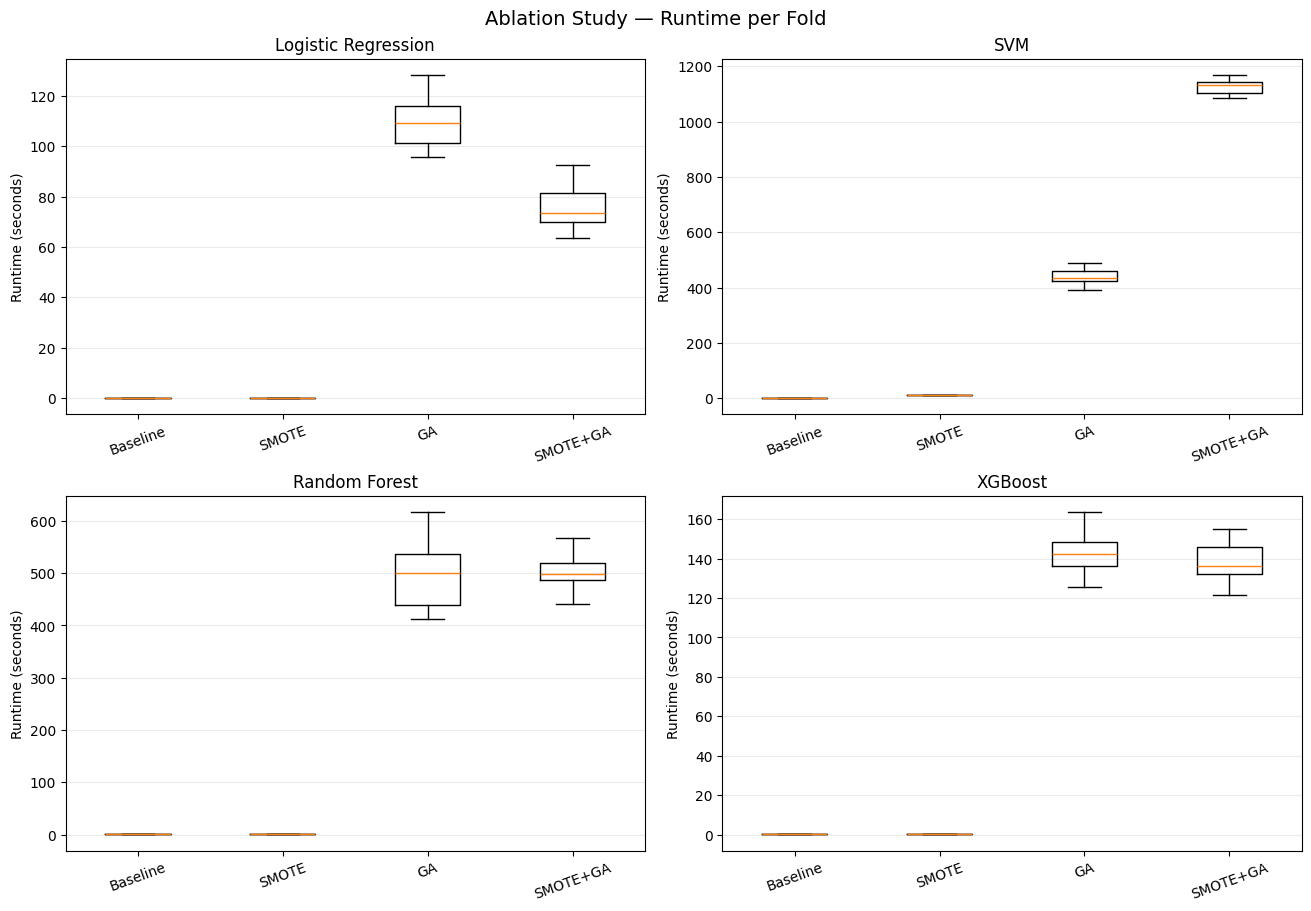

Grafik tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\bar_charts_by_metric\ablation_runtime.png


In [8]:
if "Runtime_Seconds" in all_results.columns:
    runtime_rows = []
    for model in MODELS:
        for scenario in SCENARIOS:
            sub = all_results[
                (all_results["Model"] == model) &
                (all_results["Scenario"] == scenario)
            ]
            stats = summarize_values(sub["Runtime_Seconds"])
            runtime_rows.append({
                "Model": model, "Scenario": scenario, **stats
            })
    runtime_summary = pd.DataFrame(runtime_rows)
    print("=== RINGKASAN RUNTIME (DETIK) ===")
    display(runtime_summary.round(3))
    runtime_path = OUTPUT_DIR / "ablation_runtime_descriptive_new.csv"
    runtime_summary.to_csv(runtime_path, index=False)
    print(f"CSV tersimpan: {runtime_path}")

    fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
    for ax, model in zip(axes.flatten(), MODELS):
        plot_data, labels = [], []
        for scenario in SCENARIOS:
            vals = pd.to_numeric(
                all_results.loc[
                    (all_results["Model"] == model) &
                    (all_results["Scenario"] == scenario), "Runtime_Seconds"
                ], errors="coerce"
            ).dropna().to_numpy()
            if len(vals):
                plot_data.append(vals)
                labels.append(scenario)
        if plot_data:
            ax.boxplot(plot_data, labels=labels, showfliers=False)
        ax.set_title(model)
        ax.set_ylabel("Runtime (seconds)")
        ax.tick_params(axis="x", rotation=20)
        ax.grid(axis="y", alpha=0.25)
    fig.suptitle("Ablation Study — Runtime per Fold", fontsize=14)
    runtime_plot = PLOT_DIR / "ablation_runtime.png"
    fig.savefig(runtime_plot, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Grafik tersimpan: {runtime_plot}")
else:
    print("Runtime_Seconds tidak tersedia pada data gabungan.")

## 6. Export long-format data for auditing

This CSV contains the standardized fold-level data. All tables are also displayed in the notebook; output files are saved in `ablation_descriptive_outputs/`.

In [9]:
long_path = OUTPUT_DIR / "ablation_all_scenarios_long_format_new.csv"
all_results.to_csv(long_path, index=False)

print("Ukuran data long:", all_results.shape)
display(all_results.head(10))
print(f"CSV tersimpan: {long_path}")

print("\n=== DAFTAR OUTPUT ===")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(OUTPUT_DIR))

Ukuran data long: (320, 18)


,Scenario,Model,Fold_Index,Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,Average_Precision,PR_AUC,Balanced_Accuracy,MCC,Runtime_Seconds,TN,FP,FN,TP
1,Baseline,Random Forest,2.0,0.949119,0.000000,0.00,0.997942,0.000000,0.810494,0.144897,0.136788,0.498971,-0.010043,0.548578,485.0,1.0,25.0,0.0
2,Baseline,XGBoost,3.0,0.943249,0.166667,0.04,0.989712,0.064516,0.811605,0.161658,0.147991,0.514856,0.059497,0.179171,481.0,5.0,24.0,1.0
3,Baseline,Logistic Regression,4.0,0.951076,0.000000,0.00,1.000000,0.000000,0.846996,0.280850,0.267773,0.500000,0.000000,0.054573,486.0,0.0,25.0,0.0
4,Baseline,SVM,5.0,0.951076,0.000000,0.00,1.000000,0.000000,0.672263,0.203168,0.196131,0.500000,0.000000,1.671154,486.0,0.0,25.0,0.0
6,Baseline,Random Forest,7.0,0.951076,0.500000,0.04,0.997942,0.074074,0.762881,0.194769,0.189335,0.518971,0.131081,0.525642,485.0,1.0,24.0,1.0
7,Baseline,XGBoost,8.0,0.945205,0.000000,0.00,0.993827,0.000000,0.764033,0.138354,0.127344,0.496914,-0.017429,0.101031,483.0,3.0,25.0,0.0
8,Baseline,Logistic Regression,9.0,0.951076,0.000000,0.00,1.000000,0.000000,0.813416,0.248638,0.225786,0.500000,0.000000,0.048845,486.0,0.0,25.0,0.0
9,Baseline,SVM,10.0,0.951076,0.000000,0.00,1.000000,0.000000,0.563951,0.102794,0.088564,0.500000,0.000000,1.501267,486.0,0.0,25.0,0.0
11,Baseline,Random Forest,12.0,0.951076,0.000000,0.00,1.000000,0.000000,0.813169,0.136470,0.126001,0.500000,0.000000,0.531819,486.0,0.0,25.0,0.0
12,Baseline,XGBoost,13.0,0.939335,0.200000,0.08,0.983539,0.114286,0.819342,0.165403,0.151198,0.531770,0.098949,0.107274,478.0,8.0,23.0,2.0


CSV tersimpan: D:\KULIAH\SEMESTER 7\SKRIPSI\jurnal pa irwan\codingan\ablation 9\ablation_descriptive_outputs\ablation_all_scenarios_long_format_new.csv

=== DAFTAR OUTPUT ===
.ipynb_checkpoints\ablation_all_scenarios_long_format_new-checkpoint.csv
.ipynb_checkpoints\ablation_confusion_matrix_counts_by_model_scenario_new-checkpoint.csv
.ipynb_checkpoints\Ablation_Descriptive_Analysis_Per_Metric-checkpoint.ipynb
.ipynb_checkpoints\ablation_runtime_descriptive_new-checkpoint.csv
ablation_all_scenarios_long_format_new.csv
ablation_confusion_matrix_counts_by_model_scenario_new.csv
Ablation_Descriptive_Analysis_Per_Metric.ipynb
ablation_runtime_descriptive_new.csv
bar_charts_by_metric\ablation_bar_accuracy.png
bar_charts_by_metric\ablation_bar_average_precision.png
bar_charts_by_metric\ablation_bar_balanced_accuracy.png
bar_charts_by_metric\ablation_bar_f1.png
bar_charts_by_metric\ablation_bar_mcc.png
bar_charts_by_metric\ablation_bar_pr_auc.png
bar_charts_by_metric\ablation_bar_precision.pn